<div style="border-radius:12px; overflow:hidden; border:1px solid #cbd5e1;">
  <div style="background:#172554; color:white; padding:28px;">
    <p style="color:#bfdbfe; font-size:12px;">UJIAN TENGAH SEMESTER</p>
    <h1 style="margin:8px 0;">GRAF SAINS DATA</h1>
    <p>Python Driver untuk Neo4j dan Sistem Rekomendasi</p>
    <hr style="border-color:#475569;">
    <p style="color:#93c5fd;">STUDENT INFORMATION</p>
    <h2>Naza Sulthoniyah Wahda</h2>
    <p>NIM: 23031554026</p>
    <p>Kelas: 2023D</p>
    <p>Mata Kuliah: Graf Sains Data</p>
  </div>
</div>

#
<div style="background:#20336f; padding:16px 20px; border-radius:10px; margin:12px 0;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    ENVIRONMENT SETUP
  </div>
  <h2 style="color:white; margin:7px 0; border:none;">
    Pemeriksaan Lingkungan Python dan Kernel Jupyter
  </h2>
</div>

Lingkungan Python `myenv` disiapkan sebagai kernel Jupyter di Visual Studio Code dengan memasang `ipykernel`. Selanjutnya, versi dan lokasi Python serta versi Neo4j Python Driver diperiksa untuk memastikan notebook menggunakan lingkungan yang sesuai.

![Gambar 1 a — Python Environtment-2.jpeg](<attachment:Gambar 1 a — Python Environtment-2.jpeg>)
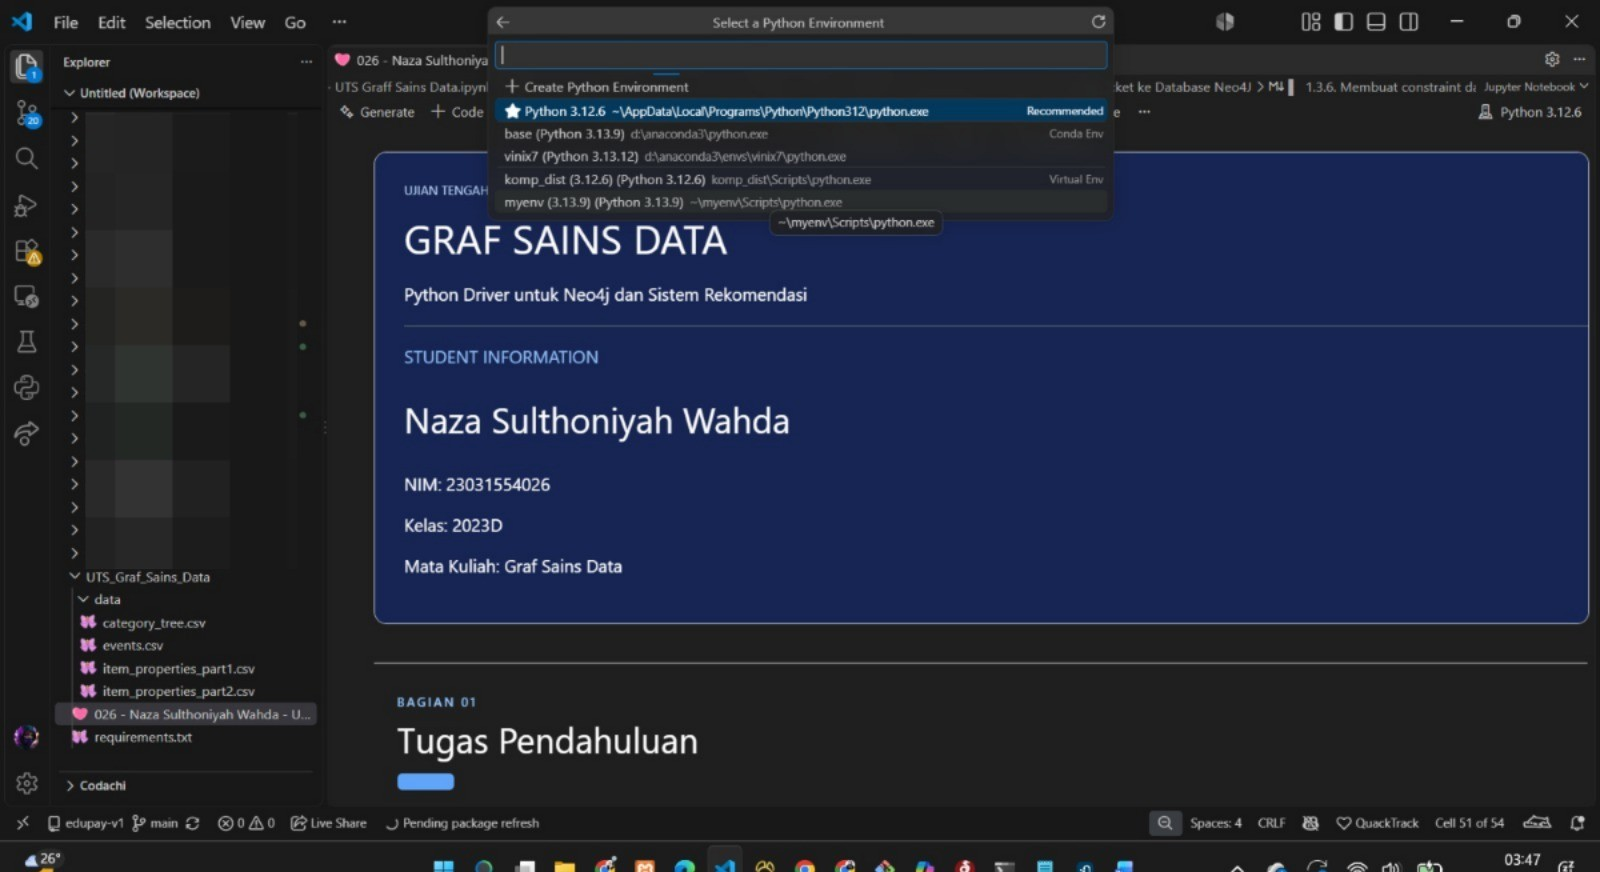

![Gambar 1 b — Python Kernel myenv Berjalan.png](<attachment:Gambar 1 b — Python Kernel myenv Berjalan.png>)
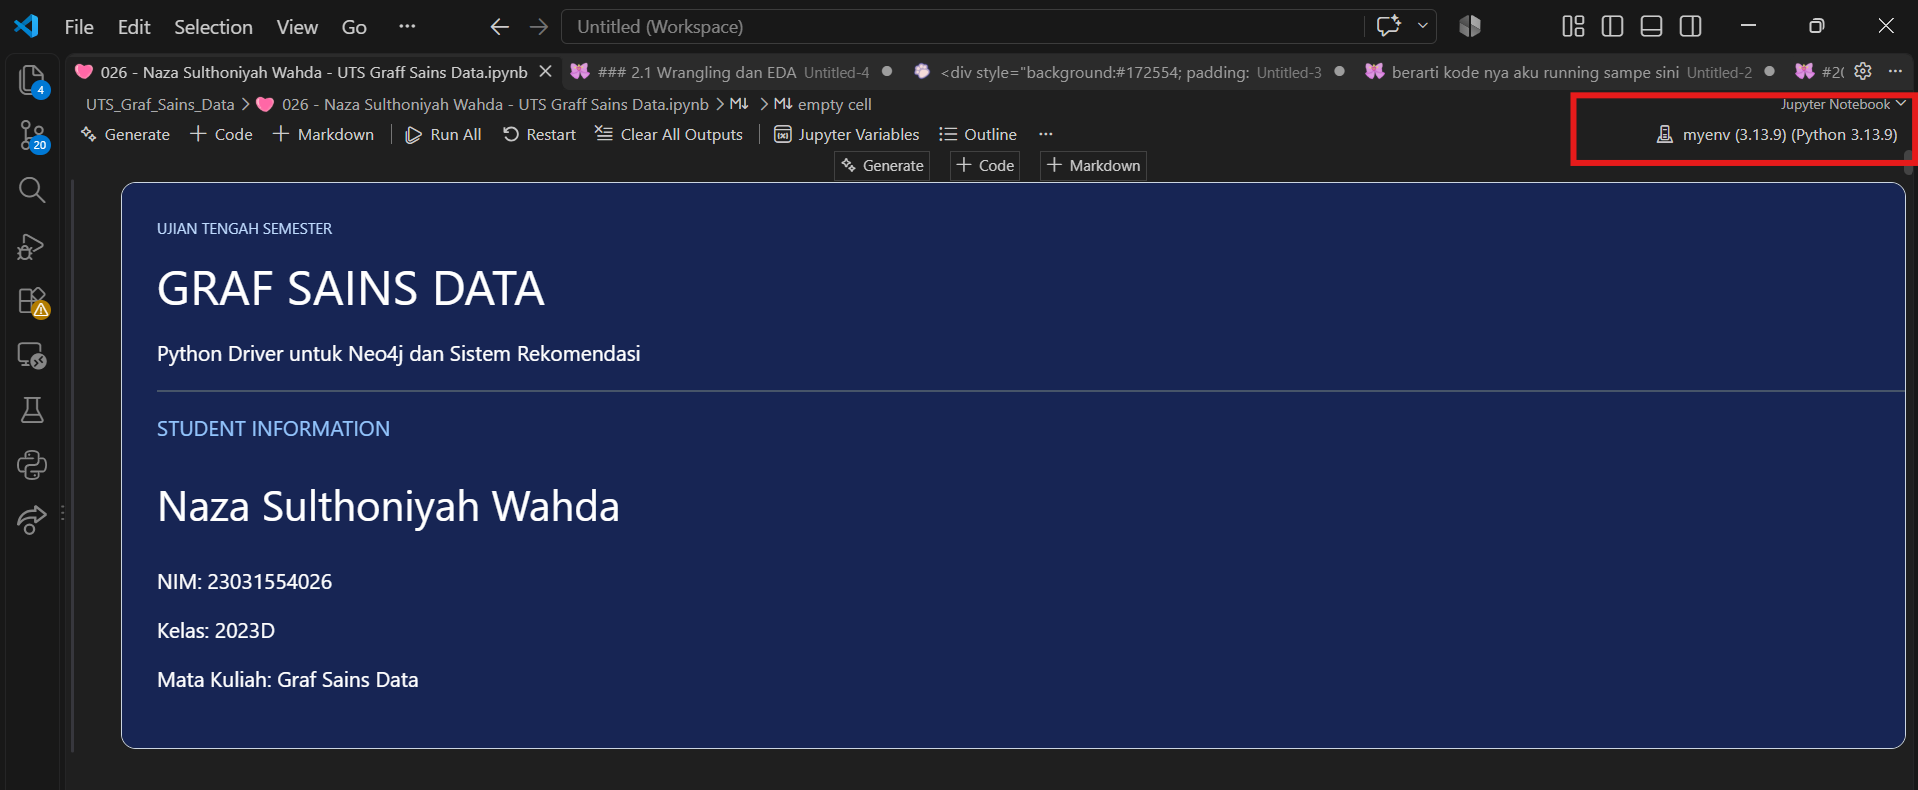

In [1]:
import sys
import neo4j

print("Versi Python:", sys.version)
print("Lokasi Python:", sys.executable)
print("Versi Neo4j:", neo4j.__version__)

Versi Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Lokasi Python: c:\Users\NAZA SULTHONIYAH\myenv\Scripts\python.exe
Versi Neo4j: 5.28.5.0


<div style="background:#60a5fa; width:100%; height:0.3px; border-radius:2px;"></div>

#
---

<div style="padding:16px 22px; border-radius:10px; margin:12px 0;">
  <div style="color:#93c5fd; font-size:12px; font-weight:600; letter-spacing:2px;">
    BAGIAN 01
  </div>
  <h2 style="color:white; margin:6px 0 10px 0; border:none;">
    Tugas Pendahuluan
  </h2>
  <div style="background:#60a5fa; width:55px; height:4px; border-radius:5px;"></div>
</div>

---

---
### **1.1 Persiapan dan Perkenalan Lingkungan**
---

#### <span style="color:#ecf2fb;"><b> ▌ 1.1.1. Pembuatan Virtual Environment </b></span> 
Virtual environment dibuat untuk mengisolasi dependensi proyek agar tidak bercampur dengan paket Python dari proyek lain. Pada UTS Graf Sains Data, virtual environment bernama `myenv` dibuat menggunakan Python 3.13.9 melalui modul `venv`, kemudian diaktifkan menggunakan PowerShell pada Windows sebelum menginstal dependensi yang diperlukan.

![Gambar 1.1.1 - Membuat Virtual Env.png](<attachment:Gambar 1.1.1 - Membuat Virtual Env.png>)
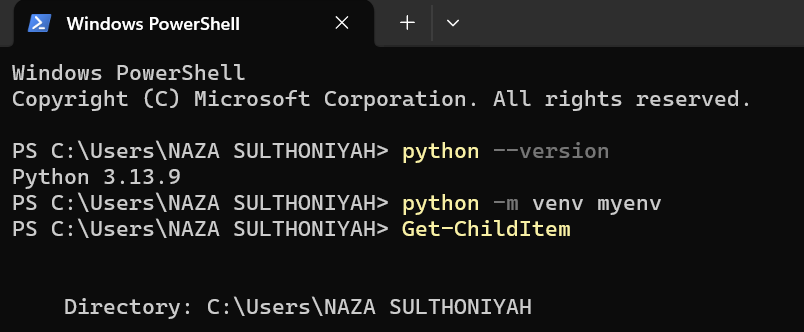

![Gambar 1.1.1 - Membuat Virtual Env (2).png](<attachment:Gambar 1.1.1 - Membuat Virtual Env (2).png>)

#### <span style="color:#ecf2fb;"><b> ▌ 1.1.2. Instalasi dan Pemeriksaan Dependensi </b></span>

![Gambar 1.1.2 - Install requirements.png](<attachment:Gambar 1.1.2 - Install requirements.png>)
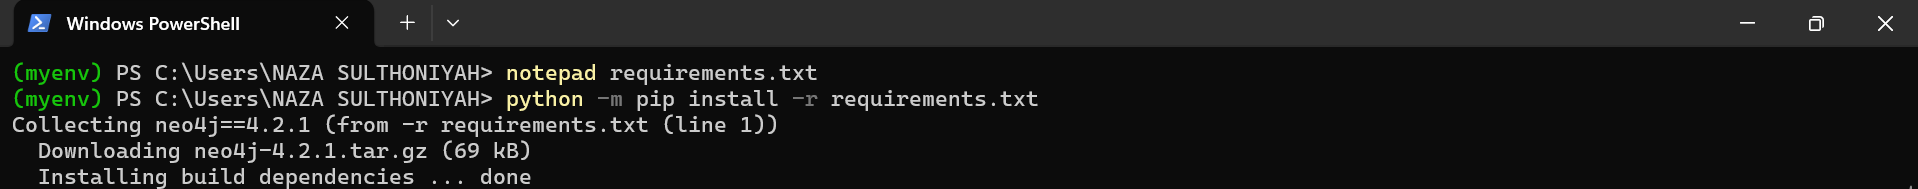

#### <span style="color:#ecf2fb;"><b> ▌ 1.1.3. Kendala Kompatibilitas Versi Neo4j Python Driver </b></span>

Pada awalnya, Neo4j Python Driver diinstal menggunakan versi `4.2.1` sesuai dengan berkas dependensi. Namun, saat kode tutorial dijalankan, muncul kendala karena versi tersebut belum mendukung `RoutingControl` dan metode `execute_query()` yang digunakan dalam kode.

Setelah dilakukan pemeriksaan, diketahui bahwa kedua fitur tersebut belum tersedia pada versi driver yang terpasang. Oleh karena itu, Neo4j Python Driver diperbarui ke versi `5.28.5`, dan versi pada `requirements.txt` juga disesuaikan.

Setelah pembaruan, `RoutingControl` berhasil diimpor dan metode `execute_query()` sudah tersedia. Dengan demikian, versi driver telah disesuaikan agar kode dapat dijalankan sesuai dengan kebutuhan tutorial.

![Gambar 1.1.3 - Kendala versi Neo4J.png](<attachment:Gambar 1.1.3 - Kendala versi Neo4J.png>)
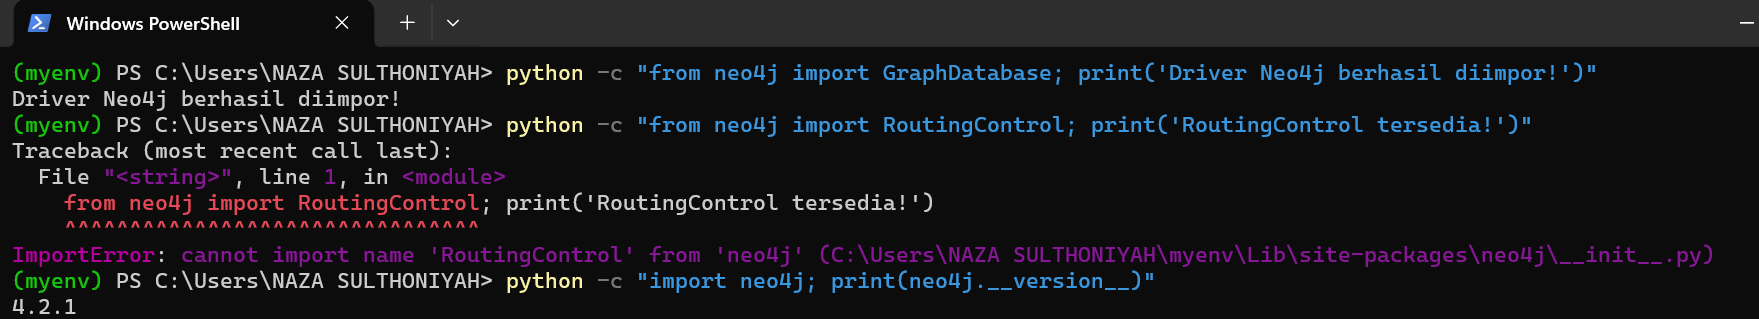

![Gambar 1.1.3 - Berhasil Upgrade Neo4j.png](<attachment:Gambar 1.1.3 - Berhasil Upgrade Neo4j.png>)
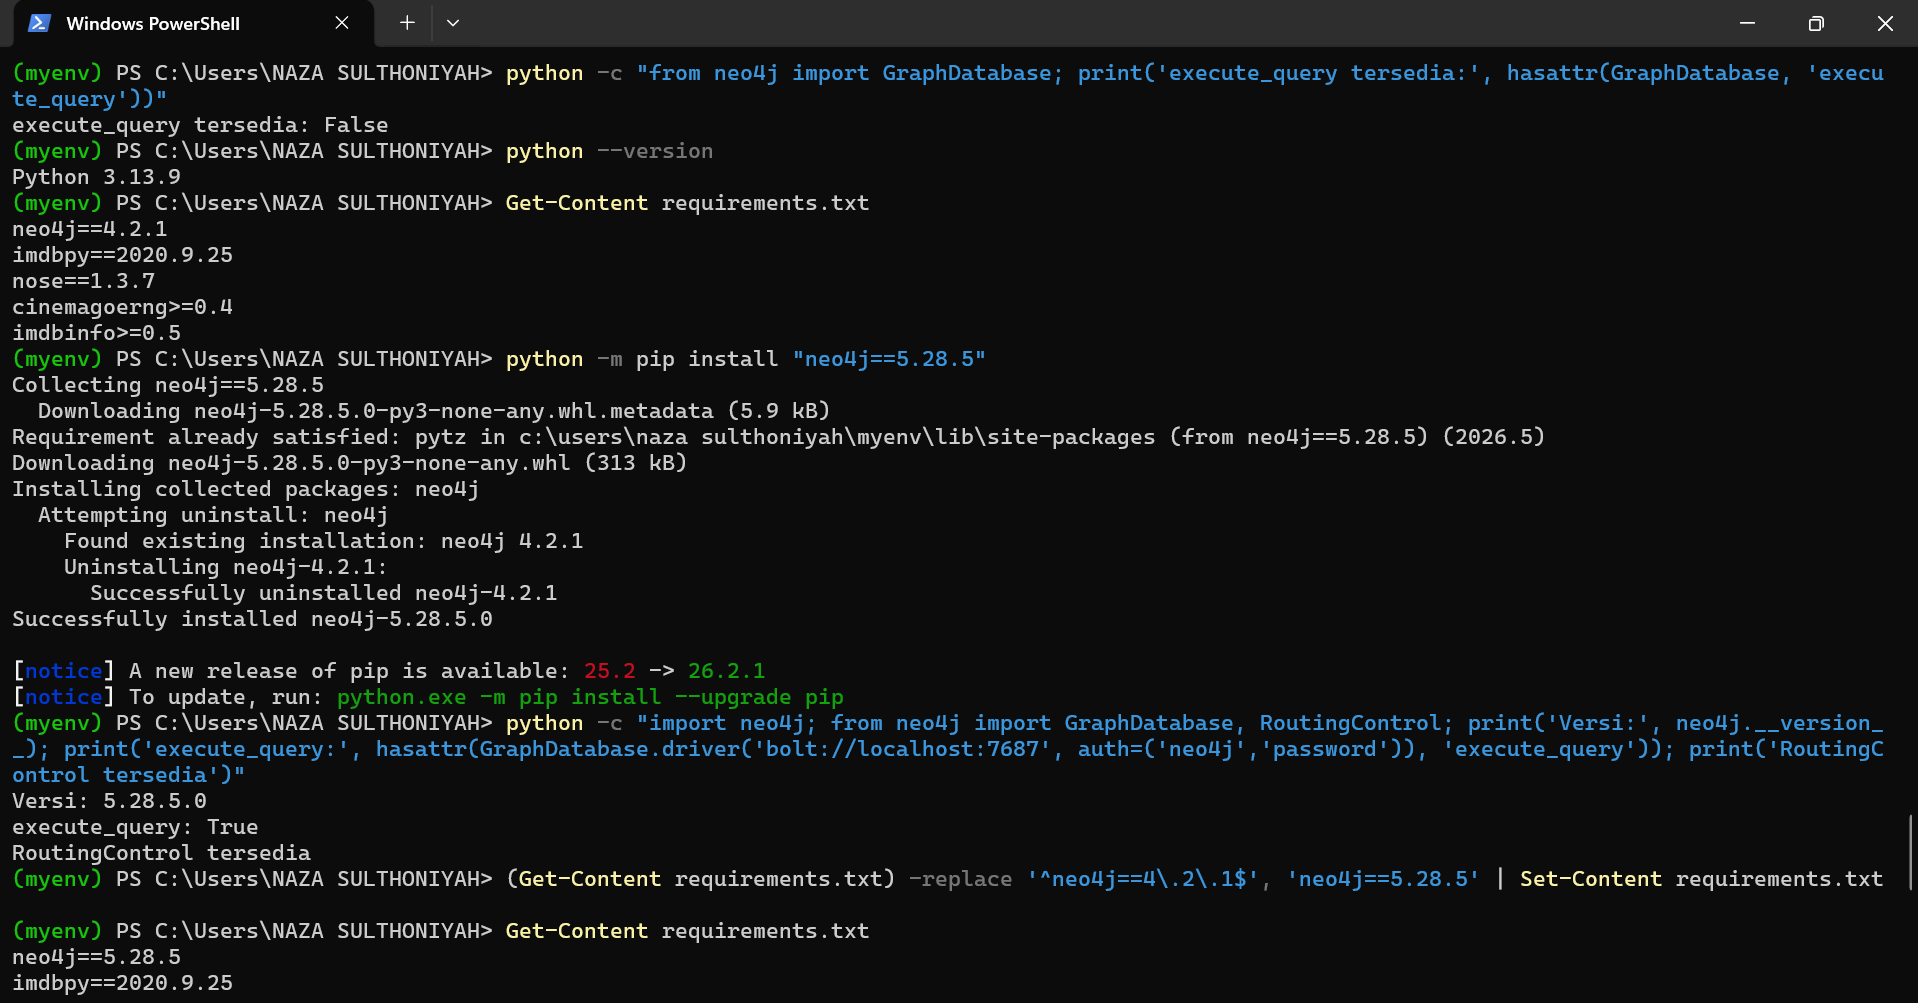

#### <span style="color:#ecf2fb;"><b> ▌ 1.1.4 Pengujian Lingkungan dan Koneksi Neo4j </b></span>

![Gambar 1.1.4 - Pengujian Koneksi ke Neo4j.png](<attachment:Gambar 1.1.4 - Pengujian Koneksi ke Neo4j.png>)
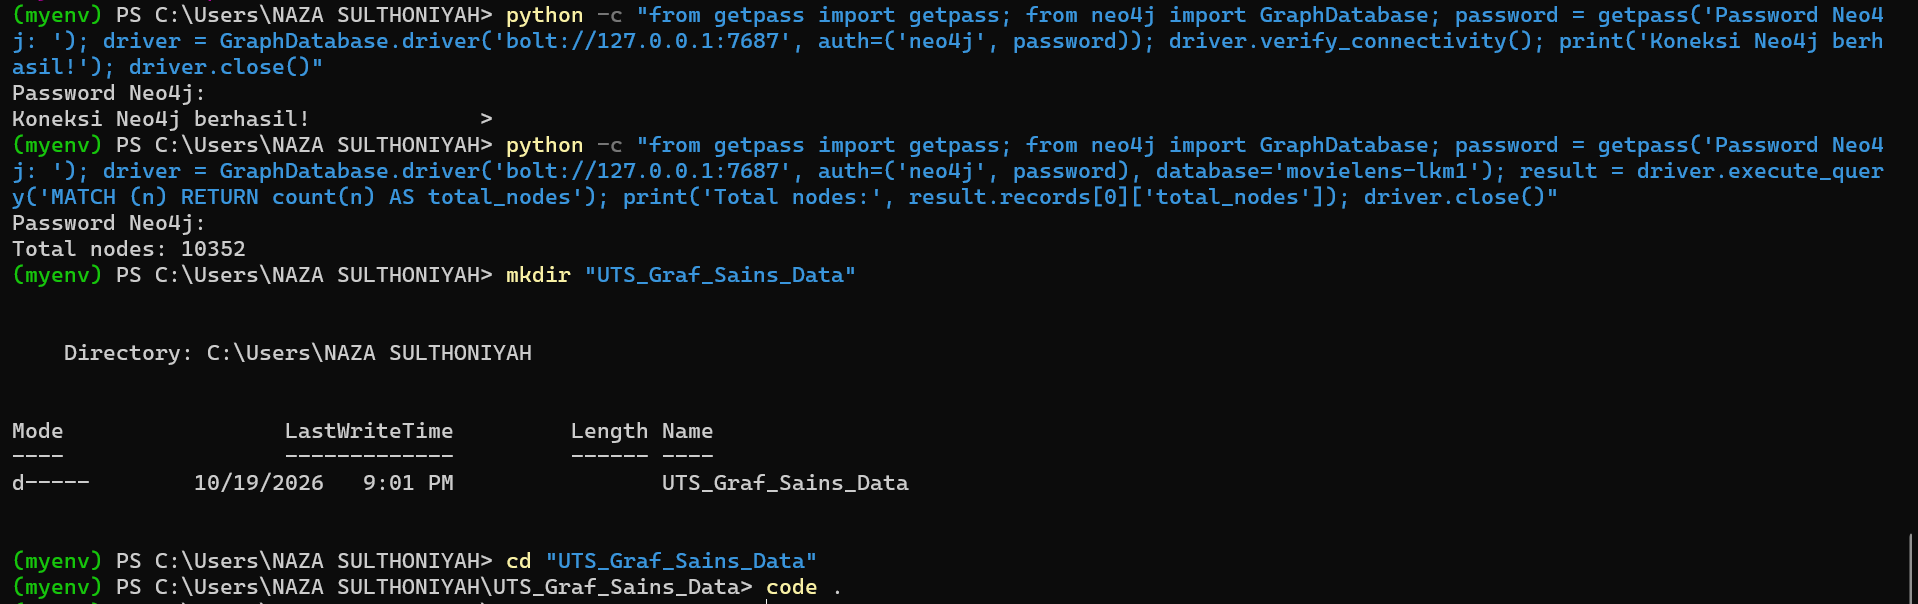

---
### **1.2 Mempelajari Penggunaan Driver Neo4J**
---

#### <span style="color:#ecf2fb;"><b> ▌ 1.2.1. Mendefinisikan string koneksi ke database Neo4J </b></span>

In [2]:
%pip install "neo4j==5.28.5"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"
AUTH = ("neo4j", getpass("Masukkan password Neo4j: "))

mencoba untuk mengecek koneksi

In [4]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


#### <span style="color:#ecf2fb;"><b> ▌ 1.2.2. Membuat node dan relationship </b></span>

In [5]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )

Kode ini mendefinisikan fungsi add_friend() untuk membuat dua node berlabel Person dan menghubungkannya dengan relationship KNOWS. Penggunaan MERGE membuat node dan relationship yang cocok digunakan kembali jika sudah ada.

#### <span style="color:#ecf2fb;"><b> ▌  1.2.3. Mengecek daftar nama teman Arthur</b></span>

In [6]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend_name
        ORDER BY friend_name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend_name"])

#### <span style="color:#ecf2fb;"><b> ▌  1.2.4. Menjalankan kode</b></span>

In [7]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Daftar teman Arthur:")
    print_friends(driver, "Arthur")

Daftar teman Arthur:
Guinevere
Lancelot
Merlin


---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">KNOWLEDGE CHECK · 01</div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">Pertanyaan Pendahuluan</h2>
  <div style="color:#cbd5e1; font-size:13px;">Checkpoint · Graf Sains Data</div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px;"></div>
</div>

<span style="color:#ecf2fb;"><b>1. Apa nama database yang digunakan pada tutorial ini?</b></span>

Database yang digunakan pada tutorial ini adalah neo4j. Nama database yang digunakan ini dapat dilihat pada parameter `database_="neo4j"` di dalam fungsi `execute_query()` yang digunakan untuk membuat dan membaca data graf.


<span style="color:#ecf2fb;"><b>2. Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam satu instance!</b></span>

Untuk mengakses database lain dalam satu instance Neo4j, dapat diakses dengan menentukan database tujuan melalui parameter database pada sesi. Misalnya `driver.session(database="nama_database")`. Daftar database yang tersedia dalam instance dapat dilihat dengan menggunakan perintah `SHOW DATABASES`. Selain itu, terdapat beberapa sintaks Cypher yang dapat digunakan untuk mengelola data graf, yaitu:

* CREATE        : membuat node atau relationship baru
* MATCH         : mencari dan membaca node atau relationship
* MERGE         : membuat node atau relationship jika belum ada, atau menggunakan data yang sudah tersedia
* SET           : menambahkan atau memperbarui properti
* DELETE        : menghapus node atau relationship
* DETACH DELETE : menghapus node beserta relationship yang terhubung dengannya



<span style="color:#ecf2fb;"><b>3. Apa jenis graf pertemanan yang telah dibuat di sini?</b></span>

Graf pertemanan yang dibuat merupakan graf berarah (directed graph). Graf tersebut terdiri atas node berlabel `Person` dan relationship berlabel `KNOWS`. Pada graf tersebut, Arthur terhubung dengan Guinevere, Lancelot, dan Merlin melalui relationship KNOWS. Arah hubungan ini menunjukkan bahwa Arthur mengenal ketiga orang tersebut, tetapi tidak menjamin/tidak berarti bahwa mereka juga mengenal Arthur.

---

<div style="background:#172554; padding:18px 22px; border-radius:10px; margin:16px 0;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">CYPHER QUERY · DATABASE MANAGEMENT</div>
  <h2 style="color:white; margin:7px 0; border:none;">CYPHER Total Reset</h2>
  <div style="color:#cbd5e1; font-size:13px;">Menghapus seluruh node dan relationship</div>
</div>

Perintah Cypher berikut digunakan untuk menghapus seluruh node beserta relationship yang terhubung pada database yang sedang dipilih.

```cypher
MATCH (n) DETACH DELETE n;
```

Keterangan:
- `MATCH (n)` digunakan untuk mencari seluruh node dalam database.
- `DETACH DELETE n` digunakan untuk menghapus node beserta seluruh relationship yang terhubung dengannya.

Perintah ini perlu digunakan dengan hati-hati, terutama pada shared database, karena seluruh data graf pada database yang dipilih dapat terhapus. Oleh karena itu, sebelum menjalankannya, perlu dipastikan bahwa database yang digunakan merupakan database latihan dan tidak menyimpan data penting.

In [8]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "MATCH (n) RETURN labels(n) AS labels, count(n) AS total",
        database_="neo4j",
    )

    for record in records:
        print(record["labels"], record["total"])

['Person'] 4


1. Menjalankan perintah reset

In [9]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, summary, _ = driver.execute_query(
        "MATCH (n) DETACH DELETE n",
        database_="neo4j",
    )

    print("Data latihan berhasil dihapus.")

Data latihan berhasil dihapus.


2. Verifikasi hasil reset

In [10]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    records, _, _ = driver.execute_query(
        "MATCH (n) RETURN count(n) AS total_nodes",
        database_="neo4j",
    )

    print("Total node setelah reset:", records[0]["total_nodes"])

Total node setelah reset: 0


Berdasarkan hasil verifikasi, jumlah node setelah perintah reset dijalankan adalah 0. Hal ini menunjukkan bahwa seluruh node beserta relationship yang terhubung pada database latihan telah berhasil dihapus menggunakan perintah `MATCH (n) DETACH DELETE n`

---

<br>

---
### **1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J**
---

#### <span style="color:#ecf2fb;"><b> ▌  1.3.1. Mengunduh dataset</b></span>

Dataset yang digunakan adalah RetailRocket E-commerce Dataset diperoleh dari Kaggle yang berisi catatan interaksi pengguna terhadap produk dalam sebuah platform e-commerce. 

Berkas dataset yang digunakan untuk proses impor interaksi adalah `events.csv`. Berkas ini memiliki lima atribut utama, yaitu `timestamp`, `visitorid`, `event`, `itemid`, dan `transactionid`. Atribut `timestamp` menyimpan waktu interaksi dalam format Unix epoch, `visitorid` merupakan identitas pengunjung, `event` menunjukkan jenis interaksi, `itemid` merupakan identitas produk, sedangkan `transactionid` menyimpan identitas transaksi jika tersedia. Dataset diunduh dan diekstrak menggunakan Windows PowerShell. Untuk mempermudah pengelolaan proyek, berkas `events.csv` kemudian disalin ke dalam subfolder `data` pada direktori proyek UTS.

![Gambar 1.3.1 - Mengunduh Dataset.png](<attachment:Gambar 1.3.1 - Mengunduh Dataset.png>)
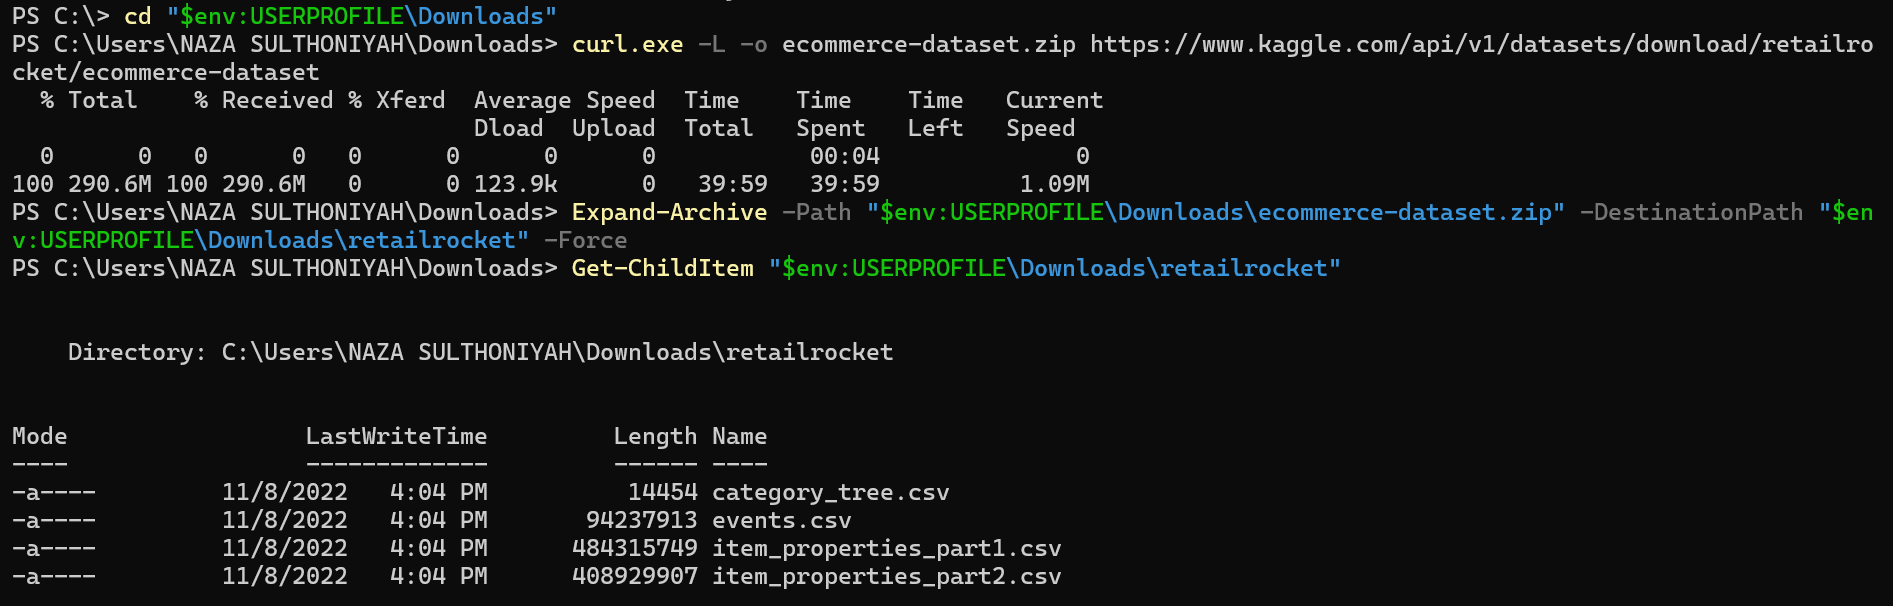

![Gambar 1.3.1 - Struktur Repo.png](<attachment:Gambar 1.3.1 - Struktur Repo.png>)
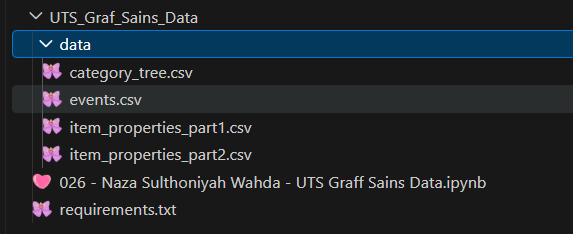

#### <span style="color:#ecf2fb;"><b> ▌  1.3.2. Memeriksa atribut dataset</b></span>

In [12]:
%pip install pandas tqdm

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.6 MB 2.0 MB/s eta 0:00:05
   ---- ----------------------------------- 1.0/9.6 MB 2.7 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.6 MB 2.7 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.6 MB 2.6 MB/s eta 0:00:03
   ---------- ----------------------------- 2.6/9.6 MB 2.6 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.6 MB 2.6 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.6 MB 2.5 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.6 MB 2.4 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.6 MB 2.4 MB/s eta 0:00:03
   --------------------- ------------------ 5.2/9.6 MB 2.4 MB/s eta 0:00:02
   ----------------------- ---------------- 5.8/9.6 MB 2.4 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.6 MB 2.5 MB/s eta 0:00:02
   ----------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
from pathlib import Path

# menentukan lokasi dataset
csv_file_path = Path("data") / "events.csv"

# memeriksa keberadaan berkas
if not csv_file_path.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path.resolve()}"
    )

print("File ditemukan:", csv_file_path.resolve())

# membaca lima baris pertama
df_sample = pd.read_csv(csv_file_path, nrows=5)

print("\nLima baris pertama:")
display(df_sample)

print("\nNama kolom:")
print(df_sample.columns.tolist())

print("\nInformasi tipe data:")
df_sample.info()

File ditemukan: C:\Users\NAZA SULTHONIYAH\UTS_Graf_Sains_Data\data\events.csv

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   timestamp      5 non-null      int64  
 1   visitorid      5 non-null      int64  
 2   event          5 non-null      str    
 3   itemid         5 non-null      int64  
 4   transactionid  0 non-null      float64
dtypes: float64(1), int64(3), str(1)
memory usage: 332.0 bytes


#### <span style="color:#ecf2fb;"><b> ▌  1.3.3. Membuat koneksi dan session Neo4j</b></span>

In [14]:
from neo4j import GraphDatabase

# membuat koneksi ke Neo4j
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


#### <span style="color:#ecf2fb;"><b> ▌  1.3.4. Menyiapkan database ratail rocket</b></span>

In [15]:
# menghapus database retailrocket jika sudah ada, ini bertujuan agar dapat menghindari duplikasi data dikarenakan saya melakukan percobaan berulang
with driver.session(database="system") as session:
    session.run(
        "DROP DATABASE retailrocket IF EXISTS"
    ).consume()

print("Perintah penghapusan database retailrocket selesai.")

Perintah penghapusan database retailrocket selesai.


In [16]:
# membuat database retailrocket
with driver.session(database="system") as session:
    session.run(
        "CREATE DATABASE retailrocket IF NOT EXISTS"
    ).consume()

    result = session.run("""
        SHOW DATABASES
        YIELD name, currentStatus
        WHERE name = 'retailrocket'
        RETURN name, currentStatus
    """)

    for record in result:
        print(
            "Database:", record["name"],
            "| Status:", record["currentStatus"]
        )

Database: retailrocket | Status: unknown


In [17]:
import time

for attempt in range(10):
    with driver.session(database="system") as session:
        result = session.run("""
            SHOW DATABASES
            YIELD name, currentStatus
            WHERE name = 'retailrocket'
            RETURN name, currentStatus
        """)
        record = result.single()

    if record is None:
        print("Database retailrocket belum ditemukan.")
    else:
        status = record["currentStatus"]
        print(f"Percobaan {attempt + 1}: {status}")

        if status == "online":
            print("Database siap digunakan!")
            break

    time.sleep(3)

Percobaan 1: online
Database siap digunakan!


#### <span style="color:#ecf2fb;"><b> ▌  1.3.5. Membuat fungsi impor data</b></span>

In [18]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )
    """

    tx.run(cypher_query, batch=batch).consume()

print("Fungsi import_batch berhasil dibuat.")

Fungsi import_batch berhasil dibuat.


#### <span style="color:#ecf2fb;"><b> ▌  1.3.6. Mengimpor dataset menggunakan batch</b></span>

In [19]:
from tqdm.auto import tqdm
from pathlib import Path
import pandas as pd

# membuat constraint agar ID visitor dan item unik
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()


# memeriksa lokasi dataset
csv_file_path = Path("data") / "events.csv"

if not csv_file_path.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path.resolve()}"
    )

# menentukan ukuran batch dan jumlah baris
batch_size = 5000

with open(csv_file_path, "r", encoding="utf-8") as file:
    total_rows = sum(1 for _ in file) - 1

total_chunks = (total_rows + batch_size - 1) // batch_size

print("Lokasi dataset:", csv_file_path.resolve())
print("Jumlah baris data:", f"{total_rows:,}")
print("Ukuran batch:", f"{batch_size:,}")
print("Jumlah batch:", f"{total_chunks:,}")

# menjalankan impor data
print("\nMemulai proses impor data ke Neo4j...")

with driver.session(database="retailrocket") as session:
    create_constraints(session)

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        # membersihkan nilai transactionid yang kosong
        chunk["transactionid"] = (
            chunk["transactionid"]
            .fillna("")
            .astype(str)
        )

        # memastikan tipe data ID dan timestamp sesuai
        chunk["timestamp"] = chunk["timestamp"].astype("int64")
        chunk["visitorid"] = chunk["visitorid"].astype("int64")
        chunk["itemid"] = chunk["itemid"].astype("int64")

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("\nProses impor batch selesai.")

c:\Users\NAZA SULTHONIYAH\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Lokasi dataset: C:\Users\NAZA SULTHONIYAH\UTS_Graf_Sains_Data\data\events.csv
Jumlah baris data: 2,756,101
Ukuran batch: 5,000
Jumlah batch: 552

Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 552/552 [05:59<00:00,  1.54it/s]


Proses impor batch selesai.


#### <span style="color:#ecf2fb;"><b> ▌ 1.3.7. Memeriksa hasil impor </b></span>

In [20]:
with driver.session(database="retailrocket") as session:
    result = session.run("""
        MATCH (v:Visitor)
        WITH count(v) AS total_visitor

        MATCH (i:Item)
        WITH total_visitor, count(i) AS total_item

        MATCH ()-[r]->()
        RETURN
            total_visitor,
            total_item,
            count(r) AS total_interaction,
            count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS total_view,
            count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS total_addtocart,
            count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS total_transaction
    """)

    record = result.single()

    print("Total Visitor:", f"{record['total_visitor']:,}")
    print("Total Item:", f"{record['total_item']:,}")
    print("Total Relasi Interaksi:", f"{record['total_interaction']:,}")
    print("Total View:", f"{record['total_view']:,}")
    print("Total Add to Cart:", f"{record['total_addtocart']:,}")
    print("Total Transaction:", f"{record['total_transaction']:,}")

Total Visitor: 1,407,580
Total Item: 235,061
Total Relasi Interaksi: 2,756,101
Total View: 2,664,312
Total Add to Cart: 69,332
Total Transaction: 22,457


<div style="background:#172554; padding:18px 22px; border-radius:10px; margin:16px 0;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">RETAILROCKET · DATA VERIFICATION</div>
  <h2 style="color:white; margin:7px 0; border:none;">Hasil Impor Dataset</h2>
  <div style="color:#cbd5e1; font-size:13px;">Database Neo4j · retailrocket</div>
</div>

Berdasarkan hasil pemeriksaan pada database `retailrocket`, diperoleh jumlah node dan relationship sebagai berikut.

<span style="color:#ecf2fb;"><b>Ringkasan Data</b></span>

| Komponen | Jumlah
|---|---:|
| Node Visitor | 1.407.580 |
| Node Item | 235.061 |
| Total relationship | 2.756.101 |

<span style="color:#ecf2fb;"><b>Rincian Interaksi</b></span>

| Jenis Interaksi | Jumlah |
|---|---:|
| VIEWED | 2.664.312 |
| ADDED_TO_CART | 69.332 |
| BOUGHT | 22.457 |
| Total | 2.756.101 |

Dataset RetailRocket berhasil diimpor ke Neo4j menggunakan batch berukuran 5.000 baris. Hasil pemeriksaan menunjukkan bahwa terdapat 1.407.580 node `Visitor` dan 235.061 node `Item`. Sementara itu, total relationship yang terbentuk sebanyak 2.756.101, terdiri atas interaksi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.

Jumlah relationship tersebut sesuai dengan jumlah baris data sumber, sehingga hasil impor menunjukkan bahwa seluruh event telah dimasukkan ke dalam graf Neo4j.

---

#
---

<div style="padding:16px 22px; border-radius:10px; margin:12px 0;">
  <div style="color:#93c5fd; font-size:12px; font-weight:600; letter-spacing:2px;">
    BAGIAN 02
  </div>
  <h2 style="color:white; margin:6px 0 10px 0; border:none;">
    Soal UTS
  </h2>
  <div style="background:#60a5fa; width:55px; height:4px; border-radius:5px;"></div>
</div>

---

---
### **2.1 Wrangling dan EDA**
---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 01
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Penentuan Periode Training dan Testing
  </h2>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>


Data interaksi pengguna dari RetailRocket E-commerce Dataset dibagi menjadi dua periode waktu. Periode pertama (P1) digunakan sebagai data training untuk membangun representasi interaksi User–Item, sedangkan periode kedua (P2) digunakan sebagai data testing untuk mengevaluasi hasil rekomendasi.

Periode yang digunakan adalah **1–31 Agustus 2015 untuk P1** dan **1–14 September 2015 untuk P2**. Pemisahan waktu ini digunakan agar proses pembentukan rekomendasi menggunakan data yang lebih dahulu terjadi, sedangkan evaluasi dilakukan menggunakan data pada periode berikutnya.

---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 02
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Penerapan Filter Timestamp dan Penyimpanan Data
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Proses filter dilakukan terhadap atribut timestamp pada berkas events.csv. Karena timestamp pada dataset menggunakan Unix epoch dalam milidetik, nilai waktu dikonversi menjadi batas numerik milidetik untuk menentukan interaksi yang termasuk ke dalam masing-masing periode. Hasil filter disimpan ke dalam dua berkas CSV terpisah, yaitu data training P1 dan data testing P2.
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

In [51]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("data")
EVENTS_PATH = DATA_DIR / "events.csv"

# periode P1: 1–31 agustus 2015
P1_START = pd.Timestamp("2015-08-01", tz="UTC")
P1_END = pd.Timestamp("2015-09-01", tz="UTC")

# periode P2: 1–14 september 2015
P2_START = pd.Timestamp("2015-09-01", tz="UTC")
P2_END = pd.Timestamp("2015-09-15", tz="UTC")

# konversi Unix epoch ke milidetik
p1_start_ms = int(P1_START.timestamp() * 1000)
p1_end_ms = int(P1_END.timestamp() * 1000)

p2_start_ms = int(P2_START.timestamp() * 1000)
p2_end_ms = int(P2_END.timestamp() * 1000)

# lokasi file keluaran
P1_PATH = DATA_DIR / "events_P1_2015-08.csv"
P2_PATH = DATA_DIR / "events_P2_2015-09_01-14.csv"

In [52]:
for path in [P1_PATH, P2_PATH]:
    if path.exists():
        path.unlink()

total_rows = 0
total_p1 = 0
total_p2 = 0

# membaca dataset per batch
for chunk in pd.read_csv(EVENTS_PATH, chunksize=250_000):
    total_rows += len(chunk)

    timestamp = pd.to_numeric(
        chunk["timestamp"], errors="coerce"
    )

    mask_p1 = (
        (timestamp >= p1_start_ms)
        & (timestamp < p1_end_ms)
    )

    mask_p2 = (
        (timestamp >= p2_start_ms)
        & (timestamp < p2_end_ms)
    )

    if mask_p1.any():
        chunk.loc[mask_p1].to_csv(
            P1_PATH,
            mode="a",
            index=False,
            header=not P1_PATH.exists()
        )
        total_p1 += int(mask_p1.sum())

    if mask_p2.any():
        chunk.loc[mask_p2].to_csv(
            P2_PATH,
            mode="a",
            index=False,
            header=not P2_PATH.exists()
        )
        total_p2 += int(mask_p2.sum())

In [53]:
print("Total baris dataset:", f"{total_rows:,}")
print("Total baris P1:", f"{total_p1:,}")
print("Total baris P2:", f"{total_p2:,}")

print("\nFile hasil filter:")
print(P1_PATH.resolve())
print(P2_PATH.resolve())


Total baris dataset: 2,756,101
Total baris P1: 553,362
Total baris P2: 260,132

File hasil filter:
C:\Users\NAZA SULTHONIYAH\UTS_Graf_Sains_Data\data\events_P1_2015-08.csv
C:\Users\NAZA SULTHONIYAH\UTS_Graf_Sains_Data\data\events_P2_2015-09_01-14.csv


#### <span style="color:#ecf2fb;"><b> ▌ Memeriksa hasil filter</b></span> 

In [54]:
p1 = pd.read_csv(P1_PATH)
p2 = pd.read_csv(P2_PATH)

def inspect_period(df, name):
    dates = pd.to_datetime(
        df["timestamp"], unit="ms", utc=True
    )

    print(f"\n{name}")
    print("=" * 40)
    print("Jumlah baris:", f"{len(df):,}")
    print("Tanggal awal:", dates.min())
    print("Tanggal akhir:", dates.max())

    print("\nKomposisi event:")
    display(
        df["event"]
        .value_counts()
        .rename_axis("Jenis Event")
        .to_frame("Jumlah")
    )

inspect_period(p1, "P1 — Training")
inspect_period(p2, "P2 — Testing")


P1 — Training
Jumlah baris: 553,362
Tanggal awal: 2015-08-01 00:00:14.822000+00:00
Tanggal akhir: 2015-08-31 23:59:58.647000+00:00

Komposisi event:


,Jumlah
Jenis Event,
view,533905
addtocart,14825
transaction,4632



P2 — Testing
Jumlah baris: 260,132
Tanggal awal: 2015-09-01 00:00:02.005000+00:00
Tanggal akhir: 2015-09-14 23:59:45.566000+00:00

Komposisi event:


,Jumlah
Jenis Event,
view,251655
addtocart,6463
transaction,2014


In [55]:
# validasi hasil filter dan rentang tanggal

assert len(p1) == total_p1, "Jumlah baris P1 tidak konsisten."
assert len(p2) == total_p2, "Jumlah baris P2 tidak konsisten."

p1_dates = pd.to_datetime(p1["timestamp"], unit="ms", utc=True)
p2_dates = pd.to_datetime(p2["timestamp"], unit="ms", utc=True)

assert (p1_dates >= P1_START).all()
assert (p1_dates < P1_END).all()
assert (p2_dates >= P2_START).all()
assert (p2_dates < P2_END).all()

assert P1_END == P2_START, "Batas waktu P1 dan P2 tidak bersambung."

print("Validasi timestamp P1 dan P2 berhasil.")
print("P1:", p1_dates.min(), "sampai", p1_dates.max())
print("P2:", p2_dates.min(), "sampai", p2_dates.max())
print("Jumlah baris P1:", f"{len(p1):,}")
print("Jumlah baris P2:", f"{len(p2):,}")

Validasi timestamp P1 dan P2 berhasil.
P1: 2015-08-01 00:00:14.822000+00:00 sampai 2015-08-31 23:59:58.647000+00:00
P2: 2015-09-01 00:00:02.005000+00:00 sampai 2015-09-14 23:59:45.566000+00:00
Jumlah baris P1: 553,362
Jumlah baris P2: 260,132


#### <span style="color:#ecf2fb;"><b> ▌ Visualisasi Komposisi Interaksi RetailRocket</b></span> 

Visualisasi ini menyajikan perbandingan jumlah interaksi pengguna pada periode training (P1) dan testing (P2). Perbandingan dilakukan berdasarkan tiga jenis event, yaitu view, addtocart, dan transaction, untuk mengetahui pola aktivitas pengguna pada kedua periode.

In [27]:
%pip install numpy matplotlib seaborn scikit-learn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 1.2 MB/s eta 0:00:08
   ---- ----------------------------------- 1.0/9.3 MB 1.5 MB/s eta 0:00:06
   ------ --------------------------------- 1.6/9.3 MB 1.5 MB/s eta 0:00:06
   -------- ------------------------------- 2.1/9.3 MB 1.7 MB/s eta 0:00:05
   ----------- ---------------------------- 2.6/9.3 MB 1.9 MB/s eta 0:00:04
   ------------- -------------------------- 3.1/9.3 MB 2.0 MB/s eta 0:00:04
   --------------- ------------------------ 3.7/9.3 MB 2.0 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.3 MB 2.1 MB/s eta 0:00:03
   -------------------- ------------------- 4.7/9.3 MB 2.1 MB/s eta 0:00:03
   ---------------------- ----------------- 5.2/9


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


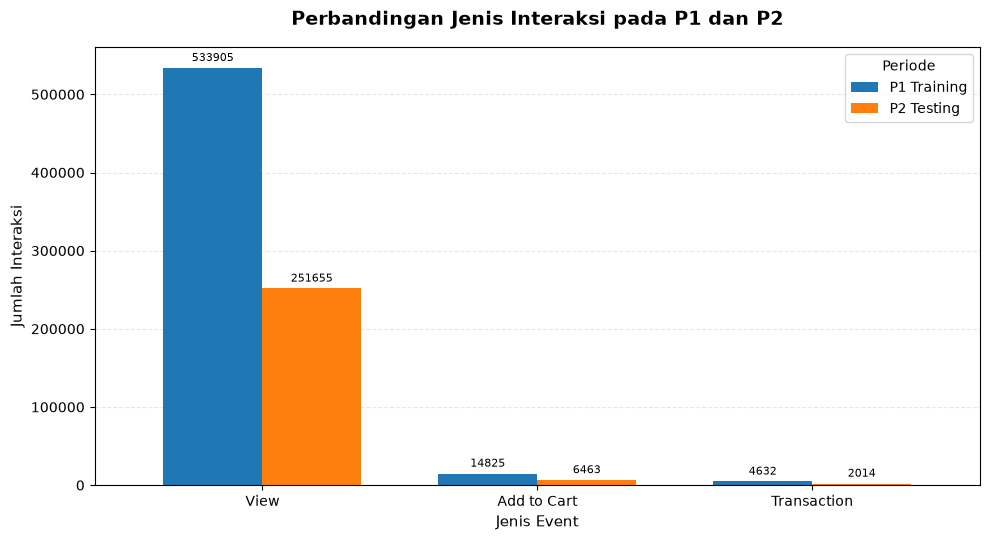

,P1 Training,P2 Testing
Jenis Interaksi,,
View,533905,251655
Add to Cart,14825,6463
Transaction,4632,2014


In [57]:
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# menghitung jumlah event pada masing-masing periode
event_order = ["view", "addtocart", "transaction"]

event_comparison = pd.DataFrame({
    "P1 Training": p1["event"].value_counts(),
    "P2 Testing": p2["event"].value_counts()
}).reindex(event_order, fill_value=0)

total_p1 = len(p1)
total_p2 = len(p2)

display(HTML("""
<div style="background:#172554;padding:22px 26px;border-radius:12px;margin:12px 0 18px 0;color:white;">
    <div style="color:#93c5fd;font-size:11px;letter-spacing:2px;font-weight:600;">RETAILROCKET · INTERACTION ANALYSIS</div>
    <h2 style="margin:8px 0; color:white;">
        Komposisi Interaksi RetailRocket
    </h2>
    <p style="margin:0; color:#cbd5e1;">
        Perbandingan jumlah event pada periode training dan testing.
    </p>
</div>
"""))

display(HTML(f"""
<div style="display:flex; gap:14px; flex-wrap:wrap; margin-bottom:18px;">
    <div style="flex:1; min-width:180px; padding:18px;border:1px solid #93c5fd; border-radius:10px;background:#eff6ff; color:#172554;">
        <div style="font-size:12px;">P1 Training</div><div style="font-size:27px; font-weight:700;">    
            {total_p1:,}
        </div>
        <div style="font-size:12px;">1–31 Agustus 2015</div>
    </div>
    <div style="flex:1; min-width:180px; padding:18px;border:1px solid #cbd5e1; border-radius:10px;background:#f8fafc; color:#172554;">
        <div style="font-size:12px;">P2 Testing</div><div style="font-size:27px; font-weight:700;">
            {total_p2:,}
        </div>
        <div style="font-size:12px;">1–14 September 2015</div>
    </div>
</div>
"""))

ax = event_comparison.plot(
    kind="bar",
    figsize=(10, 5.5),
    width=0.72
)

ax.set_title(
    "Perbandingan Jenis Interaksi pada P1 dan P2",
    fontsize=14,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Jenis Event", fontsize=11)
ax.set_ylabel("Jumlah Interaksi", fontsize=11)
ax.set_xticklabels(
    ["View", "Add to Cart", "Transaction"],
    rotation=0
)
ax.legend(title="Periode")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3,
        fontsize=8
    )

plt.tight_layout()
plt.show()

display(
    event_comparison.rename(index={
        "view": "View",
        "addtocart": "Add to Cart",
        "transaction": "Transaction"
    }).rename_axis("Jenis Interaksi")
)

Periode training (P1) memiliki 553.362 interaksi, sedangkan periode testing (P2) memiliki 260.132 interaksi. Pada kedua periode, event view mendominasi dengan 533.905 interaksi pada P1 dan 251.655 interaksi pada P2. Selanjutnya, event addtocart tercatat sebanyak 14.825 interaksi pada P1 dan 6.463 interaksi pada P2, sedangkan event transaction masing-masing berjumlah 4.632 dan 2.014 interaksi. Hasil tersebut menunjukkan bahwa aktivitas melihat produk lebih sering terjadi dibandingkan aktivitas menambahkan produk ke keranjang dan melakukan transaksi. Selanjutnya, pemeriksaan komposisi subgraf dilakukan untuk mengetahui jumlah node pengunjung, node produk, dan relationship pada setiap periode berdasarkan data yang tersimpan di Neo4j.

---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 03
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Pemeriksaan Komposisi Subgraph Berdasarkan Periode
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Pemeriksaan ini bertujuan untuk mengetahui karakteristik subgraph pada setiap periode sebagai dasar pembentukan Vector Space Model (VSM) pada tahap berikutnya.
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

In [58]:
driver.verify_connectivity()

# query Cypher untuk menghitung komposisi subgraph
query_subgraph = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
RETURN
    count(DISTINCT v) AS total_visitor,
    count(DISTINCT i) AS total_item,
    count(r) AS total_interaction,
    count(CASE WHEN type(r) = 'VIEWED' THEN 1 END) AS total_view,
    count(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 END) AS total_addtocart,
    count(CASE WHEN type(r) = 'BOUGHT' THEN 1 END) AS total_transaction
"""

def get_subgraph_stats(start_ms, end_ms, period):
    with driver.session(database="retailrocket") as session:
        record = session.run(query_subgraph, start_ms=start_ms, end_ms=end_ms).single()

    return {
        "Periode": period,
        "Jumlah Visitor": record["total_visitor"],
        "Jumlah Item": record["total_item"],
        "Jumlah Relationship": record["total_interaction"],
        "VIEWED": record["total_view"],
        "ADDED_TO_CART": record["total_addtocart"],
        "BOUGHT": record["total_transaction"]
    }

# menghitung komposisi subgraph P1 dan P2
stats_p1 = get_subgraph_stats(p1_start_ms, p1_end_ms, "P1 - Training")
stats_p2 = get_subgraph_stats(p2_start_ms, p2_end_ms, "P2 - Testing")
stats_df = pd.DataFrame([stats_p1, stats_p2])
display(stats_df.set_index("Periode"))

,Jumlah Visitor,Jumlah Item,Jumlah Relationship,VIEWED,ADDED_TO_CART,BOUGHT
Periode,,,,,,
P1 - Training,311128,114050,553362,533905,14825,4632
P2 - Testing,150026,75390,260132,251655,6463,2014


#### <span style="color:#ecf2fb;"><b> ▌  Komposisi Subgraph pada Periode Training dan Testing</b></span> 

Berdasarkan hasil query menggunakan Python API Neo4j, subgraph periode training (P1) terdiri atas **311.128 simpul `Visitor`** dan **114.050 simpul `Item`**, dengan total **553.362 relationship**. Sementara itu, subgraph periode testing (P2) terdiri atas **150.026 simpul `Visitor`** dan **75.390 simpul `Item`**, dengan total **260.132 relationship**.

Relationship pada kedua periode terdiri atas tiga jenis, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Pada P1, masing-masing berjumlah 533.905, 14.825, dan 4.632 relationship. Adapun pada P2, jumlahnya berturut-turut adalah 251.655, 6.463, dan 2.014 relationship.

Query Cypher yang digunakan menerapkan `MATCH` untuk mencocokkan pola simpul `Visitor` yang terhubung dengan simpul `Item` melalui relationship. Klausa `WHERE` membatasi data berdasarkan rentang timestamp masing-masing periode. Selanjutnya, `count(DISTINCT v)` dan `count(DISTINCT i)` menghitung jumlah simpul unik, sedangkan `count(r)` menghitung total relationship. Fungsi `count(CASE WHEN type(r) = ... THEN 1 END)` digunakan untuk menghitung relationship berdasarkan jenis interaksinya. Parameter waktu dikirim melalui Python API menggunakan `session.run()`, kemudian hasil query diolah menjadi DataFrame untuk ditampilkan.

Hasil tersebut menunjukkan bahwa P1 memiliki jumlah simpul dan relationship lebih besar dibandingkan P2, dengan interaksi `VIEWED` mendominasi kedua periode. Komposisi ini memberikan gambaran karakteristik subgraph yang digunakan sebagai dasar pembentukan representasi data menggunakan *Vector Space Model* (VSM).

---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 04
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Vector Space Modelling (VSM) pada Simpul User
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Vector Space Modelling (VSM) digunakan untuk merepresentasikan interaksi pengguna dan produk dalam bentuk matriks numerik.
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

Pada proyeksi User–Item, setiap baris merepresentasikan satu pengguna (`Visitor`), sedangkan setiap kolom merepresentasikan satu produk (`Item`). Nilai pada matriks menunjukkan jumlah interaksi antara pengguna dan produk selama periode training (P1). Apabila pengguna berinteraksi dengan suatu produk beberapa kali, nilai matriks akan mencerminkan frekuensi interaksi tersebut. Sebaliknya, pasangan pengguna dan produk yang tidak memiliki interaksi pada periode training akan memiliki nilai nol. Karena jumlah kemungkinan pasangan pengguna dan produk sangat besar, matriks direpresentasikan menggunakan format sparse matrix. Representasi ini menyimpan nilai yang tidak nol secara efisien sehingga lebih sesuai untuk data interaksi e-commerce yang memiliki banyak pasangan tanpa interaksi.

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# mengambil pasangan user-item dari data training
train = p1[["visitorid", "itemid"]].copy()

# menghitung frekuensi interaksi setiap pasangan user-item
ui = (
    train.groupby(["visitorid", "itemid"])
    .size()
    .reset_index(name="interaction_count")
)

# membuat daftar user dan item yang muncul pada P1
users = np.sort(ui["visitorid"].unique())
items = np.sort(ui["itemid"].unique())

# membuat pemetaan ID ke indeks matriks
user_to_idx = {user: idx for idx, user in enumerate(users)}
item_to_idx = {item: idx for idx, item in enumerate(items)}

rows = ui["visitorid"].map(user_to_idx).to_numpy()
cols = ui["itemid"].map(item_to_idx).to_numpy()
values = ui["interaction_count"].to_numpy(dtype=np.float32)

# membentuk sparse matrix User-Item
X_user_item = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users), len(items))
)

# menghitung karakteristik matriks
total_cells = X_user_item.shape[0] * X_user_item.shape[1]
density = X_user_item.nnz / total_cells
sparsity = 1 - density

print("=== KARAKTERISTIK VSM USER ===")
print("Jumlah user:", len(users))
print("Jumlah item:", len(items))
print("Shape matriks:", X_user_item.shape)
print("Jumlah pasangan user-item unik:", X_user_item.nnz)
print("Jumlah seluruh sel matriks:", f"{total_cells:,}")
print("Density:", f"{density:.8%}")
print("Sparsity:", f"{sparsity:.8%}")

print("\nContoh pasangan user-item:")
display(ui.head(10))

=== KARAKTERISTIK VSM USER ===
Jumlah user: 311128
Jumlah item: 114050
Shape matriks: (311128, 114050)
Jumlah pasangan user-item unik: 438980
Jumlah seluruh sel matriks: 35,484,148,400
Density: 0.00123712%
Sparsity: 99.99876288%

Contoh pasangan user-item:


,visitorid,itemid,interaction_count
0,1,72028,1
1,2,216305,2
2,2,259884,1
3,2,325215,3
4,2,342816,2
5,3,385090,1
6,6,65273,1
7,6,253615,1
8,6,344723,4
9,10,248766,1


In [31]:
%pip install networkx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 2.3 MB/s eta 0:00:01
   -------------- ------------------------- 0.8/2.1 MB 2.1 MB/s eta 0:00:01
   ------------------- -------------------- 1.0/2.1 MB 1.7 MB/s eta 0:00:01
   ----------------------------- ---------- 1.6/2.1 MB 1.8 MB/s eta 0:00:01
   ---------------------------------- ----- 1.8/2.1 MB 1.8 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 1.8 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


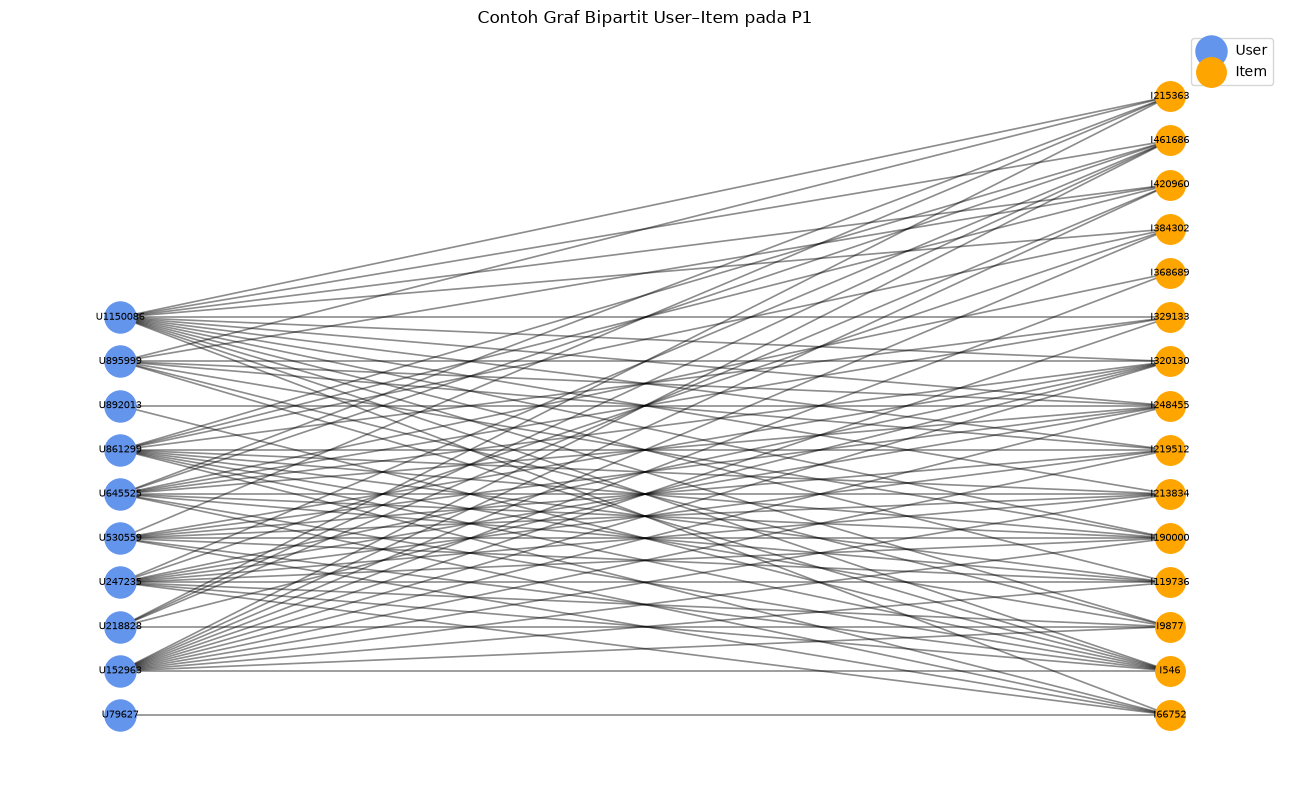

Jumlah simpul pada graf sampel: 25
Jumlah edge pada graf sampel: 85


In [60]:
import networkx as nx

# memilih 10 user dengan jumlah interaksi tertinggi
top_users = (train["visitorid"].value_counts().head(10).index)

# mengambil pasangan user-item yang melibatkan user terpilih
sample_edges = ui[ui["visitorid"].isin(top_users)].copy()

# memilih maksimal 15 item yang paling banyak berinteraksi
top_items = (sample_edges.groupby("itemid")["interaction_count"].sum().nlargest(15).index)
sample_edges = sample_edges[sample_edges["itemid"].isin(top_items)]

# membentuk graf bipartit sampel
G_user_item = nx.Graph()
for _, row in sample_edges.iterrows():
    user_node = f"U{row['visitorid']}"
    item_node = f"I{row['itemid']}"
    G_user_item.add_node(user_node,bipartite="user")
    G_user_item.add_node(item_node,bipartite="item")
    G_user_item.add_edge(user_node,item_node,weight=int(row["interaction_count"]))

# mengatur posisi user dan item pada dua sisi
user_nodes = [
    n for n, d in G_user_item.nodes(data=True)
    if d["bipartite"] == "user"
]
item_nodes = [
    n for n, d in G_user_item.nodes(data=True)
    if d["bipartite"] == "item"
]

pos = {}
pos.update(
    (node, (0, i))
    for i, node in enumerate(user_nodes)
)
pos.update(
    (node, (1, i))
    for i, node in enumerate(item_nodes)
)

plt.figure(figsize=(13, 8))
nx.draw_networkx_nodes(G_user_item,pos,nodelist=user_nodes,node_color="cornflowerblue",node_size=500,label="User")
nx.draw_networkx_nodes(G_user_item,pos,nodelist=item_nodes,node_color="orange",node_size=450,label="Item")
nx.draw_networkx_edges(G_user_item,pos,alpha=0.45,width=1.2)
nx.draw_networkx_labels(G_user_item,pos,font_size=7)

plt.title("Contoh Graf Bipartit User–Item pada P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul pada graf sampel:", G_user_item.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_user_item.number_of_edges())


#### <span style="color:#ecf2fb;"><b> ▌ Vector Space Modelling pada Simpul User </b></span> 

<span style="color:#ecf2fb;"><b>Penjelasan hasil</b></span>

Vector Space Modelling (VSM) diterapkan pada data training (P1) untuk merepresentasikan interaksi antara pengguna dan produk dalam bentuk matriks numerik. Setiap baris merepresentasikan satu simpul Visitor, sedangkan setiap kolom merepresentasikan satu simpul Item. Nilai setiap elemen matriks menunjukkan frekuensi interaksi antara pengguna dan produk yang bersangkutan selama periode training.

Berdasarkan hasil pembentukan matriks, terdapat 311.128 User dan 114.050 Item, sehingga matriks User–Item memiliki dimensi dan shape sebesar (311128, 114050). Matriks tersebut memiliki 438.980 pasangan User–Item dengan nilai nonzero dari total 35.484.148.400 kemungkinan pasangan. Dengan demikian, density matriks sebesar 0,00123712%, sedangkan sparsity mencapai 99,99876288%.

Tingginya nilai sparsity menunjukkan bahwa sebagian besar kemungkinan pasangan User–Item tidak memiliki interaksi yang tercatat pada periode training. Oleh karena itu, matriks disimpan menggunakan format Compressed Sparse Row (CSR) dari pustaka SciPy. Format ini menyimpan elemen nonzero secara efisien tanpa perlu menyimpan seluruh nilai nol secara eksplisit.


<span style="color:#ecf2fb;"><b>Visualisasi graf bipartit menggunakan NetworkX</b></span>

Visualisasi menggunakan NetworkX dilakukan untuk memperlihatkan struktur hubungan antara simpul User dan Item. Untuk memudahkan pembacaan graf, dipilih 10 User dengan jumlah interaksi tertinggi, kemudian diambil maksimal 15 Item dengan frekuensi interaksi tertinggi di antara User terpilih tersebut.

Berdasarkan hasil visualisasi, graf sampel terdiri atas 25 simpul dan 85 edge. Simpul User ditempatkan di sisi kiri, sedangkan simpul Item ditempatkan di sisi kanan. Setiap edge merepresentasikan hubungan interaksi antara User dan Item, dengan atribut weight yang menunjukkan frekuensi interaksi pasangan tersebut.

Graf yang dihasilkan merupakan subgraf sampel untuk visualisasi, bukan keseluruhan graf User–Item pada periode training. Pemilihan sampel dilakukan agar hubungan antarsimpul lebih mudah diamati dan divisualisasikan.

<span style="color:#ecf2fb;"><b>Kesimpulan</b></span>

Hasil VSM menunjukkan bahwa data interaksi RetailRocket dapat direpresentasikan dalam bentuk matriks User–Item berdimensi tinggi dengan tingkat sparsity yang sangat besar. Penggunaan matriks sparse memungkinkan representasi tersebut disimpan secara lebih efisien, sedangkan visualisasi graf bipartit menggunakan NetworkX membantu memperlihatkan pola hubungan antara pengguna dan produk. Representasi ini dapat digunakan sebagai dasar untuk analisis hubungan User–Item dan pengembangan sistem rekomendasi.

---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 05
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Vector Space Modelling (VSM) pada Simpul Item
  </h2>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

Vector Space Modelling (VSM) pada simpul Item digunakan untuk merepresentasikan setiap produk berdasarkan interaksinya dengan pengguna selama periode training (P1). Dalam proyeksi Item–User, setiap baris merepresentasikan satu produk (`Item`), sedangkan setiap kolom merepresentasikan satu pengguna (`Visitor`).

Nilai pada matriks menunjukkan frekuensi interaksi antara produk dan pengguna. Dengan representasi ini, setiap produk dapat dipandang sebagai vektor yang menggambarkan pola interaksi penggunanya. Produk dengan pola pengguna yang serupa berpotensi memiliki nilai kemiripan (similarity) yang tinggi. Seperti pada VSM User, matriks Item–User dibentuk menggunakan sparse matrix karena tidak semua produk berinteraksi dengan seluruh pengguna. Representasi ini membantu menghemat penyimpanan dan menjadi dasar untuk membandingkan kemiripan antarproduk.

In [61]:
from scipy.sparse import csr_matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# VSM Item-User merupakan transpose dari matriks User-Item
X_item_user = X_user_item.T.tocsr()

# karakteristik matriks Item-User
total_cells_item = X_item_user.shape[0] * X_item_user.shape[1]
density_item = X_item_user.nnz / total_cells_item
sparsity_item = 1 - density_item

print("=== KARAKTERISTIK VSM ITEM ===")
print("Jumlah item:", X_item_user.shape[0])
print("Jumlah user:", X_item_user.shape[1])
print("Shape matriks:", X_item_user.shape)
print("Jumlah pasangan item-user unik:", X_item_user.nnz)
print("Jumlah seluruh sel matriks:", f"{total_cells_item:,}")
print("Density:", f"{density_item:.8%}")
print("Sparsity:", f"{sparsity_item:.8%}")

print("\nContoh pasangan Item-User:")
display(ui[["itemid", "visitorid", "interaction_count"]].head(10))

=== KARAKTERISTIK VSM ITEM ===
Jumlah item: 114050
Jumlah user: 311128
Shape matriks: (114050, 311128)
Jumlah pasangan item-user unik: 438980
Jumlah seluruh sel matriks: 35,484,148,400
Density: 0.00123712%
Sparsity: 99.99876288%

Contoh pasangan Item-User:


,itemid,visitorid,interaction_count
0,72028,1,1
1,216305,2,2
2,259884,2,1
3,325215,2,3
4,342816,2,2
5,385090,3,1
6,65273,6,1
7,253615,6,1
8,344723,6,4
9,248766,10,1


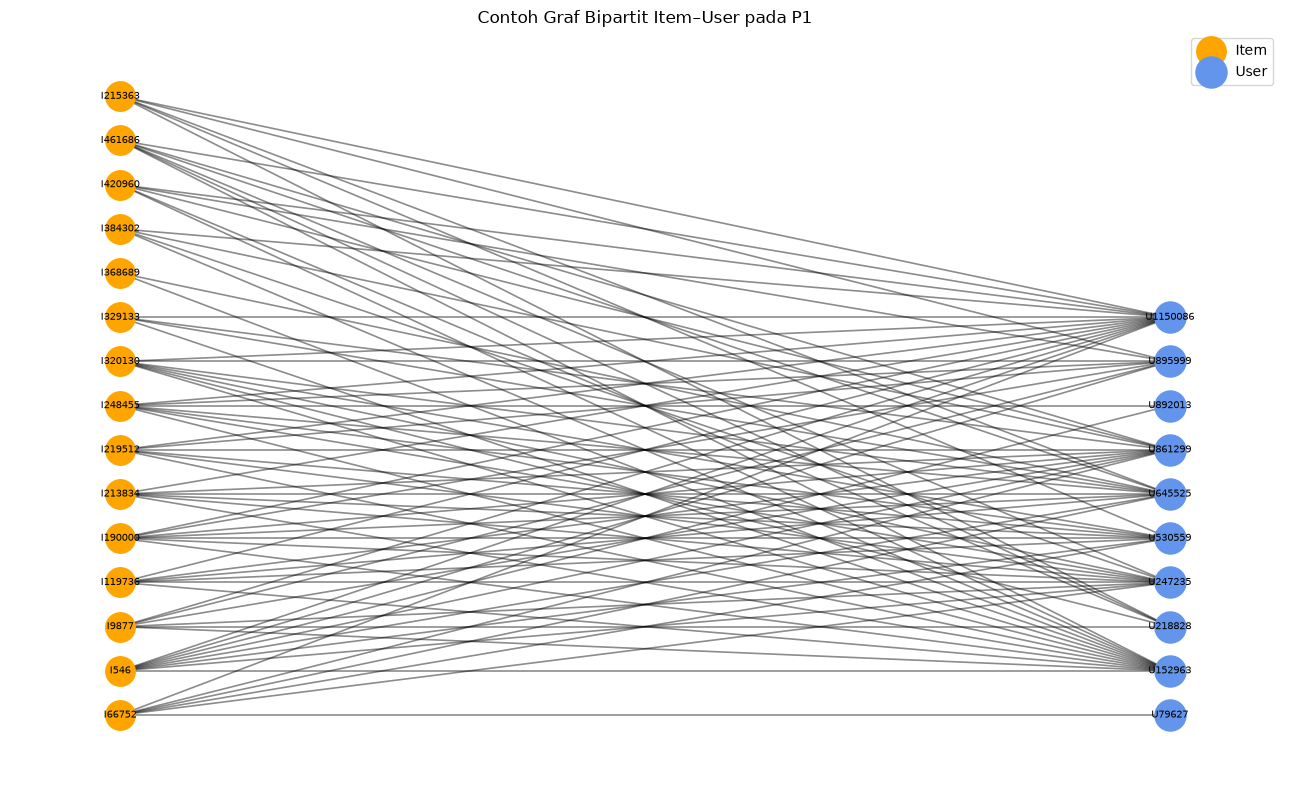

Jumlah simpul pada graf sampel: 25
Jumlah edge pada graf sampel: 85


In [62]:
# menggunakan sampel hubungan yang sama dengan bagian VSM User
G_item_user = nx.Graph()
for _, row in sample_edges.iterrows():
    item_node = f"I{row['itemid']}"
    user_node = f"U{row['visitorid']}"

    G_item_user.add_node(item_node, bipartite="item")
    G_item_user.add_node(user_node, bipartite="user")
    G_item_user.add_edge(item_node,user_node,weight=int(row["interaction_count"]))

item_nodes_plot = [
    n for n, d in G_item_user.nodes(data=True)
    if d["bipartite"] == "item"
]
user_nodes_plot = [
    n for n, d in G_item_user.nodes(data=True)
    if d["bipartite"] == "user"
]

pos_item = {}
pos_item.update(
    (node, (0, i))
    for i, node in enumerate(item_nodes_plot)
)
pos_item.update(
    (node, (1, i))
    for i, node in enumerate(user_nodes_plot)
)

plt.figure(figsize=(13, 8))
nx.draw_networkx_nodes(G_item_user, pos_item,nodelist=item_nodes_plot,node_color="orange",node_size=450,label="Item")
nx.draw_networkx_nodes(G_item_user, pos_item,nodelist=user_nodes_plot,node_color="cornflowerblue",node_size=500,label="User")
nx.draw_networkx_edges(G_item_user, pos_item,alpha=0.45,width=1.2)
nx.draw_networkx_labels(G_item_user, pos_item,font_size=7)

plt.title("Contoh Graf Bipartit Item–User pada P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul pada graf sampel:", G_item_user.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_item_user.number_of_edges())

#### <span style="color:#ecf2fb;"><b> ▌ Representasi Matriks Item–User dan Visualisasi Graf Bipartit</b></span> 

<span style="color:#ecf2fb;"><b>Penjelasan hasil</b></span>

Vector Space Modelling (VSM) pada simpul Item dibentuk dengan melakukan transpose terhadap matriks User–Item yang telah dihasilkan pada tahap sebelumnya. Proses ini mengubah orientasi matriks sehingga setiap baris merepresentasikan satu simpul `Item`, sedangkan setiap kolom merepresentasikan satu simpul `Visitor`. Nilai setiap elemen tetap menunjukkan frekuensi interaksi antara produk dan pengguna selama periode training (P1).

Berdasarkan hasil pembentukan matriks, terdapat **114.050 Item** dan **311.128 User**, sehingga matriks Item–User memiliki dimensi dan *shape* sebesar **(114050, 311128)**. Matriks tersebut memiliki **438.980 nilai nonzero** dari total **35.484.148.400 kemungkinan pasangan Item–User**. Dengan demikian, *density* matriks sebesar **0,00123712%**, sedangkan *sparsity* mencapai **99,99876288%**.

Nilai jumlah nonzero, *density*, dan *sparsity* sama dengan matriks User–Item karena proses transpose hanya mengubah orientasi baris dan kolom, tanpa mengubah nilai elemen matriks. Matriks Item–User juga disimpan menggunakan format *Compressed Sparse Row* (CSR) agar penyimpanan nilai nonzero lebih efisien.

<span style="color:#ecf2fb;"><b>Visualisasi graf bipartit menggunakan NetworkX</b></span>

Visualisasi NetworkX digunakan untuk memperlihatkan hubungan antara simpul Item dan User berdasarkan pasangan interaksi pada periode training. Graf yang ditampilkan menggunakan sampel hubungan yang sama dengan visualisasi VSM User, tetapi posisi kedua kelompok simpul dibalik. Simpul Item ditempatkan di sisi kiri, sedangkan simpul User berada di sisi kanan.

Berdasarkan hasil visualisasi, graf sampel terdiri atas **25 simpul dan 85 edge**. Setiap *edge* merepresentasikan hubungan interaksi antara suatu Item dan User, sedangkan atribut *weight* menunjukkan frekuensi interaksi pada pasangan tersebut.

Graf ini merupakan subgraf sampel untuk memudahkan pengamatan struktur hubungan Item–User, bukan keseluruhan graf pada dataset. Karena menggunakan pasangan interaksi yang sama dengan visualisasi sebelumnya, jumlah simpul dan *edge* tetap sama meskipun posisi kelompok simpul dibalik.

<span style="color:#ecf2fb;"><b>Kesimpulan</b></span>

Hasil VSM menunjukkan bahwa interaksi produk dan pengguna dapat direpresentasikan dalam matriks Item–User dengan *shape* sebesar **(114050, 311128)**. Tingkat *sparsity* yang tinggi menunjukkan bahwa hanya sebagian kecil kemungkinan pasangan Item–User yang memiliki interaksi tercatat. Penggunaan matriks sparse membantu menghemat penyimpanan, sedangkan visualisasi graf bipartit menggunakan NetworkX memberikan gambaran mengenai hubungan antara produk dan pengguna. Representasi Item–User ini dapat digunakan sebagai dasar untuk menghitung kemiripan antarproduk berdasarkan pola interaksinya dengan pengguna.

---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 06
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Perbandingan Proyeksi User dan Item
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Evaluasi Dimensi Matriks, Efisiensi Penyimpanan, dan Tujuan Analisis
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

In [63]:
comparison_vsm = pd.DataFrame([
    {
        "Proyeksi": "User–Item",
        "Shape": X_user_item.shape,
        "Jumlah baris": X_user_item.shape[0],
        "Jumlah kolom": X_user_item.shape[1],
        "Nilai nonzero": X_user_item.nnz,
        "Sparsity": 1 - X_user_item.nnz /
                    (X_user_item.shape[0] * X_user_item.shape[1])
    },
    {
        "Proyeksi": "Item–User",
        "Shape": X_item_user.shape,
        "Jumlah baris": X_item_user.shape[0],
        "Jumlah kolom": X_item_user.shape[1],
        "Nilai nonzero": X_item_user.nnz,
        "Sparsity": 1 - X_item_user.nnz /
                    (X_item_user.shape[0] * X_item_user.shape[1])
    }
])

display(comparison_vsm)

,Proyeksi,Shape,Jumlah baris,Jumlah kolom,Nilai nonzero,Sparsity
0,User–Item,"(311128, 114050)",311128,114050,438980,0.999988
1,Item–User,"(114050, 311128)",114050,311128,438980,0.999988


#### <span style="color:#ecf2fb;"><b> ▌ Perbandingan proyeksi User dan Item</b></span> 

<span style="color:#ecf2fb;"><b>Perbandingan karakteristik VSM</b></span>

Berdasarkan hasil eksplorasi pada soal 4 dan 5, matriks User–Item memiliki *shape* sebesar **(311128, 114050)**, sedangkan matriks Item–User memiliki *shape* sebesar **(114050, 311128)**. Kedua matriks memiliki **438.980 nilai nonzero** dan *sparsity* sebesar **99,99876288%**. Kesamaan tersebut terjadi karena matriks Item–User merupakan hasil transpose dari matriks User–Item. Proses transpose mengubah orientasi baris dan kolom, tetapi tidak mengubah nilai interaksi yang direpresentasikan maupun jumlah elemen nonzero.

<span style="color:#ecf2fb;"><b>Proyeksi yang dipilih</b></span>

Untuk analisis ini, **proyeksi Item–User dipilih sebagai dasar perhitungan kemiripan antarproduk (*item similarity*)**. Pada proyeksi tersebut, setiap produk direpresentasikan sebagai vektor berdasarkan frekuensi interaksinya dengan pengguna. Kemiripan antarproduk kemudian dapat dihitung menggunakan *cosine similarity* untuk mengidentifikasi produk yang memiliki pola interaksi pengguna serupa. Dari sisi penyimpanan, kedua proyeksi sama-sama menggunakan format sparse matrix sehingga nilai nol tidak perlu disimpan secara eksplisit. Oleh karena itu, transpose tidak secara otomatis membuat salah satu proyeksi lebih hemat memori. Perbedaan utamanya terletak pada orientasi data dan objek yang akan dibandingkan.

<span style="color:#ecf2fb;"><b>Pertimbangan efisiensi</b></span>

Matriks Item–User memiliki 114.050 baris yang merepresentasikan produk. Namun, apabila seluruh pasangan produk dibandingkan sekaligus, matriks kemiripan yang dihasilkan dapat berukuran **114050 × 114050**. Perhitungan tersebut berpotensi membutuhkan sumber daya komputasi dan memori yang besar. Untuk mengurangi beban komputasi, perhitungan kemiripan dapat dilakukan secara selektif terhadap satu produk acuan. Selanjutnya, lima produk dengan nilai *cosine similarity* tertinggi dapat dipilih sebagai hasil analisis untuk digunakan pada tahap berikutnya.

<span style="color:#ecf2fb;"><b>Kesimpulan</b></span>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Proyeksi</th>
      <th>Shape</th>
      <th>Jumlah baris</th>
      <th>Jumlah kolom</th>
      <th>Nilai nonzero</th>
      <th>Sparsity</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>User–Item</td>
      <td>(311128, 114050)</td>
      <td>311128</td>
      <td>114050</td>
      <td>438980</td>
      <td>0.999988</td>
    </tr>
    <tr>
      <th>1</th>
      <td>Item–User</td>
      <td>(114050, 311128)</td>
      <td>114050</td>
      <td>311128</td>
      <td>438980</td>
      <td>0.999988</td>
    </tr>
  </tbody>
</table>
</div>

Berdasarkan hasil perbandingan, **Item–User merupakan proyeksi yang lebih sesuai untuk tujuan analisis kemiripan antarproduk**, sedangkan User–Item lebih sesuai apabila tujuan analisisnya adalah membandingkan pola interaksi antar pengguna. Kedua proyeksi memiliki jumlah nilai nonzero dan tingkat *sparsity* yang sama sehingga tidak ada perbedaan mendasar dalam efisiensi penyimpanan sparse matrix. Pemilihan proyeksi ditentukan oleh tujuan analisis dan cara perhitungan kemiripan akan dilakukan.


---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 07
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Perhitungan dan Penyimpanan Similarity Antarproduk
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Cosine Similarity, Query Cypher, dan Integrasi dengan Neo4j
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px;border-radius:10px;"></div>
</div>

#### <span style="color:#ecf2fb;"><b> ▌ Perhitungan Cosine Similarity pada Proyeksi Item–User</b></span>

Perhitungan cosine similarity dilakukan untuk mengidentifikasi lima produk yang memiliki pola interaksi paling mirip dengan produk acuan. Produk acuan dipilih berdasarkan jumlah interaksi tertinggi pada data training (P1). Kemiripan dihitung antara vektor produk acuan dan seluruh vektor produk pada matriks Item–User, kemudian lima kandidat dengan nilai similarity positif tertinggi dipilih sebagai hasil analisis.

In [40]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import numpy as np

# memilih produk acuan dengan jumlah interaksi terbanyak pada P1
item_popularity = (
    ui.groupby("itemid")["interaction_count"]
    .sum()
    .sort_values(ascending=False)
)

reference_item = int(item_popularity.index[0])
reference_idx = item_to_idx[reference_item]

print("Produk acuan:", reference_item)
print(
    "Jumlah interaksi produk acuan:",
    int(item_popularity.iloc[0])
)

# menghitung cosine similarity produk acuan terhadap seluruh produk dalam matriks Item-User
similarity_scores = cosine_similarity(
    X_item_user[reference_idx],
    X_item_user
).ravel()

# menyusun hasil similarity
similarity_df = pd.DataFrame({
    "itemid": items.astype(int),
    "similarity": similarity_scores
})

# menghapus produk acuan dari kandidat rekomendasi
similarity_df = similarity_df[
    similarity_df["itemid"] != reference_item
].copy()

# mengambil lima produk dengan similarity tertinggi
top5_similarity = (
    similarity_df[similarity_df["similarity"] > 0]
    .sort_values(
        by=["similarity", "itemid"],
        ascending=[False, True]
    )
    .head(5)
    .reset_index(drop=True)
)

top5_similarity.insert(
    0,
    "reference_item",
    reference_item
)

print("\n=== TOP 5 ITEM DENGAN SIMILARITY TERTINGGI ===")
display(top5_similarity)

Produk acuan: 187946
Jumlah interaksi produk acuan: 2650

=== TOP 5 ITEM DENGAN SIMILARITY TERTINGGI ===


,reference_item,itemid,similarity
0,187946,127784,0.057290
1,187946,311292,0.052876
2,187946,284176,0.037244
3,187946,133549,0.033309
4,187946,270992,0.030528


#### <span style="color:#ecf2fb;"><b> ▌  Pemeriksaan Relationship Similarity pada Neo4j</b></span>

Sebelum menyimpan hasil perhitungan, dilakukan pemeriksaan terhadap jumlah relationship `SIMILAR_TO` yang sudah terhubung dengan produk acuan. Pemeriksaan ini bertujuan untuk mengetahui apakah relationship similarity sudah tersedia pada graf Neo4j sebelum proses penyimpanan dilakukan.

In [41]:
query_before = """
MATCH (a:Item {itemId: $reference_item})
OPTIONAL MATCH (a)-[r:SIMILAR_TO]->(b:Item)
RETURN count(r) AS existing_similarity_relationships
"""

with driver.session(database="retailrocket") as session:
    before_result = session.run(
        query_before,
        reference_item=reference_item
    ).single()

print(
    "Jumlah relasi SIMILAR_TO sebelum penyimpanan:",
    before_result["existing_similarity_relationships"]
)

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.UnknownRelationshipTypeWarning} {category: UNRECOGNIZED} {title: The provided relationship type is not in the database.} {description: One of the relationship types in your query is not available in the database, make sure you didn't misspell it or that the label is available when you run this statement in your application (the missing relationship type is: SIMILAR_TO)} {position: line: 3, column: 23, offset: 64} for query: '\nMATCH (a:Item {itemId: $reference_item})\nOPTIONAL MATCH (a)-[r:SIMILAR_TO]->(b:Item)\nRETURN count(r) AS existing_similarity_relationships\n'


Jumlah relasi SIMILAR_TO sebelum penyimpanan: 0


#### <span style="color:#ecf2fb;"><b> ▌ Penyimpanan Hasil Similarity ke dalam Graf Neo4j</b></span>

Lima produk terpilih beserta nilai cosine similarity-nya disiapkan dalam bentuk data terstruktur, kemudian disimpan ke dalam graf Neo4j menggunakan relationship `SIMILAR_TO`. Setiap relationship menghubungkan produk acuan dengan produk yang memiliki kemiripan, serta menyimpan properti nilai similarity, periode data, dan metode perhitungan.

Penyimpanan menggunakan klausa `MERGE` untuk mencocokkan atau membuat relationship yang sesuai, sedangkan klausa `SET` digunakan untuk memperbarui properti relationship tersebut.

In [42]:
similarity_rows = [
    {
        "source_item": int(reference_item),
        "target_item": int(row.itemid),
        "similarity": float(row.similarity),
        "period": "P1",
        "method": "cosine"
    }
    for row in top5_similarity.itertuples(index=False)
]

query_save_similarity = """
UNWIND $rows AS row

MATCH (a:Item {itemId: row.source_item})
MATCH (b:Item {itemId: row.target_item})

MERGE (a)-[r:SIMILAR_TO]->(b)

SET r.similarity = row.similarity,
    r.period = row.period,
    r.method = row.method

RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity,
    r.period AS period,
    r.method AS method
ORDER BY similarity DESC, similar_item ASC
"""

with driver.session(database="retailrocket") as session:
    saved_result = session.run(
        query_save_similarity,
        rows=similarity_rows
    )
    saved_records = [
        record.data() for record in saved_result
    ]

saved_similarity_df = pd.DataFrame(saved_records)
display(saved_similarity_df)

,reference_item,similar_item,similarity,period,method
0,187946,127784,0.057290,P1,cosine
1,187946,311292,0.052876,P1,cosine
2,187946,284176,0.037244,P1,cosine
3,187946,133549,0.033309,P1,cosine
4,187946,270992,0.030528,P1,cosine


#### <span style="color:#ecf2fb;"><b> ▌  Verifikasi Lima Produk dengan Similarity Tertinggi</b></span>

Setelah proses penyimpanan selesai, dilakukan pembacaan kembali terhadap relationship `SIMILAR_TO` untuk produk acuan pada periode P1. Query Cypher mengurutkan relationship berdasarkan nilai similarity tertinggi dan membatasi hasil menjadi lima produk. Tahap ini digunakan untuk memeriksa bahwa hasil perhitungan telah tersimpan dan dapat diakses kembali dari Neo4j.

In [43]:
query_top5 = """
MATCH (a:Item {itemId: $reference_item})
      -[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC, similar_item ASC
LIMIT 5
"""

with driver.session(database="retailrocket") as session:
    result = session.run(
        query_top5,
        reference_item=reference_item
    )
    neo4j_top5 = [
        record.data() for record in result
    ]

display(pd.DataFrame(neo4j_top5))

,reference_item,similar_item,similarity
0,187946,127784,0.057290
1,187946,311292,0.052876
2,187946,284176,0.037244
3,187946,133549,0.033309
4,187946,270992,0.030528


#### <span style="color:#ecf2fb;"><b> ▌ Pemeriksaan Properti Relationship Similarity</b></span>

Pemeriksaan terakhir dilakukan untuk melihat properti produk acuan, relationship `SIMILAR_TO`, dan produk yang terhubung dengannya. Informasi tersebut ditampilkan melalui Python API Neo4j untuk memastikan bahwa struktur hubungan dan atribut similarity dapat dibaca kembali dari graf.

In [44]:
query_graph = """
MATCH (a:Item {itemId: $reference_item})
      -[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN a, r, b
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="retailrocket") as session:
    graph_result = session.run(
        query_graph,
        reference_item=reference_item
    )

    for record in graph_result:
        print(
            "Produk acuan:", dict(record["a"]),
            "| Similarity:", dict(record["r"]),
            "| Produk mirip:", dict(record["b"])
        )

Produk acuan: {'itemId': 187946} | Similarity: {'period': 'P1', 'method': 'cosine', 'similarity': 0.057289984077215195} | Produk mirip: {'itemId': 127784}
Produk acuan: {'itemId': 187946} | Similarity: {'period': 'P1', 'method': 'cosine', 'similarity': 0.05287626385688782} | Produk mirip: {'itemId': 311292}
Produk acuan: {'itemId': 187946} | Similarity: {'period': 'P1', 'method': 'cosine', 'similarity': 0.03724396601319313} | Produk mirip: {'itemId': 284176}
Produk acuan: {'itemId': 187946} | Similarity: {'period': 'P1', 'method': 'cosine', 'similarity': 0.03330891579389572} | Produk mirip: {'itemId': 133549}
Produk acuan: {'itemId': 187946} | Similarity: {'period': 'P1', 'method': 'cosine', 'similarity': 0.030528126284480095} | Produk mirip: {'itemId': 270992}


#### <span style="color:#ecf2fb;"><b> ▌ Perhitungan Cosine Similarity Menggunakan Python </b></span>

Perhitungan *cosine similarity* dilakukan menggunakan matriks Item–User yang dibentuk dari data training periode P1 (1–31 Agustus 2015). Produk acuan dipilih berdasarkan jumlah interaksi tertinggi selama periode tersebut. Berdasarkan hasil perhitungan, produk dengan ID `187946` dipilih sebagai produk acuan dengan jumlah **2.650 interaksi**. Selanjutnya, kemiripan dihitung antara vektor produk acuan dan seluruh vektor produk pada matriks Item–User. Produk acuan dikeluarkan dari daftar kandidat agar tidak muncul sebagai rekomendasi bagi dirinya sendiri. Lima produk dengan nilai *cosine similarity* positif tertinggi kemudian dipilih sebagai hasil analisis.

Berdasarkan hasil perhitungan Python, diperoleh lima produk dengan nilai *cosine similarity* tertinggi sebagai berikut.

| Produk Acuan | Produk Mirip | Cosine Similarity |
|---:|---:|---:|
| 187946 | 127784 | 0,057290 |
| 187946 | 311292 | 0,052876 |
| 187946 | 284176 | 0,037244 |
| 187946 | 133549 | 0,033309 |
| 187946 | 270992 | 0,030528 |

Nilai *cosine similarity* menunjukkan tingkat kemiripan arah vektor interaksi antara produk acuan dan produk kandidat. Semakin tinggi nilainya, semakin mirip pola interaksi pengguna yang direpresentasikan oleh kedua produk. Nilai similarity yang positif menunjukkan adanya kemiripan pola interaksi, meskipun tingkat kemiripannya berbeda pada setiap pasangan produk.

#### <span style="color:#ecf2fb;"><b> ▌ Soal 7(a) — Query Cypher untuk Mendapatkan Lima Produk dengan Similarity Tertinggi </b></span>

Bagian ini bertujuan untuk mengambil lima produk dengan nilai similarity tertinggi terhadap produk acuan `187946` dari graf Neo4j. Hasil perhitungan Python digunakan sebagai sumber nilai similarity yang kemudian disimpan dalam relationship `SIMILAR_TO`. Query Cypher berikut digunakan untuk membaca lima produk dengan similarity tertinggi pada periode P1.

```cypher
MATCH (a:Item {itemId: $reference_item})-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC, similar_item ASC
LIMIT 5
```

Parameter `reference_item` diisi menggunakan ID produk acuan `187946`. Klausa `MATCH` digunakan untuk mencari produk acuan beserta relationship `SIMILAR_TO` yang menghubungkannya dengan produk lain. Klausa `WHERE` membatasi hasil pada periode P1, sedangkan `ORDER BY` mengurutkan produk berdasarkan nilai similarity tertinggi. Jika terdapat nilai similarity yang sama, pengurutan dilanjutkan berdasarkan ID produk. Klausa `LIMIT 5` memastikan bahwa hanya lima produk yang ditampilkan.

Hasil query ditampilkan melalui Python API Neo4j dalam bentuk DataFrame. Hasil tersebut menunjukkan lima produk yang memiliki nilai similarity tertinggi terhadap produk acuan berdasarkan relationship `SIMILAR_TO` yang tersimpan pada graf.

#### <span style="color:#ecf2fb;"><b> ▌ Soal 7(b) — Penyimpanan Nilai Similarity ke dalam Graf Neo4j </b></span>

Setelah nilai similarity dihitung menggunakan Python, lima pasangan produk beserta nilai kemiripannya disimpan ke dalam graf Neo4j melalui relationship `SIMILAR_TO`. Relationship ini menghubungkan produk acuan dengan masing-masing produk yang memiliki nilai kemiripan tertinggi.

Penyimpanan dilakukan menggunakan klausa `MERGE` untuk mencocokkan relationship yang sesuai atau membuatnya apabila belum tersedia. Selanjutnya, klausa `SET` digunakan untuk menyimpan atau memperbarui properti relationship. Setiap relationship menyimpan tiga properti berikut.

* `similarity`: nilai *cosine similarity* antara produk acuan dan produk kandidat.
* `period`: periode data yang digunakan, yaitu P1.
* `method`: metode perhitungan similarity, yaitu cosine.

Berikut merupakan query Cypher yang digunakan untuk menyimpan hasil perhitungan ke dalam graf.

```cypher
UNWIND $rows AS row

MATCH (a:Item {itemId: row.source_item})
MATCH (b:Item {itemId: row.target_item})

MERGE (a)-[r:SIMILAR_TO]->(b)

SET r.similarity = row.similarity,
    r.period = row.period,
    r.method = row.method

RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity,
    r.period AS period,
    r.method AS method
ORDER BY similarity DESC, similar_item ASC
```

Parameter `$rows` berisi lima pasangan produk beserta nilai similarity yang dihasilkan oleh Python. Klausa `UNWIND` memproses setiap pasangan produk, sedangkan `MATCH` mencari simpul produk acuan dan produk kandidat. Klausa `MERGE` memastikan relationship yang sesuai tersedia, sementara `SET` digunakan untuk menyimpan atau memperbarui nilai similarity beserta informasi periode dan metode perhitungannya.

Setelah proses penyimpanan selesai, dilakukan pembacaan kembali menggunakan query Cypher untuk memverifikasi bahwa nilai similarity telah tersimpan pada graf Neo4j. Query yang digunakan adalah sebagai berikut.

```cypher
MATCH (a:Item {itemId: $reference_item})-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC, similar_item ASC
LIMIT 5
```

Hasil query ditampilkan kembali melalui Python API Neo4j. Nilai similarity yang diperoleh dibandingkan dengan hasil perhitungan Python untuk memastikan bahwa informasi kemiripan produk telah tersimpan dengan benar.

#### <span style="color:#ecf2fb;"><b> ▌ Kesimpulan </b></span>

Berdasarkan hasil eksplorasi, *cosine similarity* dapat digunakan untuk mengidentifikasi produk yang memiliki pola interaksi pengguna serupa berdasarkan representasi Item–User. Lima produk dengan nilai similarity tertinggi terhadap produk acuan berhasil dipilih melalui perhitungan Python. Selanjutnya, hasil perhitungan disimpan sebagai relationship `SIMILAR_TO` pada graf Neo4j dan dibaca kembali menggunakan query Cypher.

Dengan demikian, proses perhitungan similarity menggunakan Python dan penyimpanan hasilnya pada graf Neo4j telah diterapkan. Hasil similarity tidak hanya tersedia dalam bentuk tabel, tetapi juga terintegrasi ke dalam graf sehingga dapat digunakan kembali untuk analisis hubungan antarproduk dan pengembangan sistem rekomendasi.

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 08
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Visualisasi Graf Sebelum dan Sesudah Perhitungan Similarity
  </h2>
  <div style="color:#cbd5e1; font-size:13px;">
    Perbandingan Struktur Relationship pada Graf Neo4j
  </div>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

#### <span style="color:#ecf2fb;"><b> ▌ Kondisi Graf Sebelum Perhitungan Similarity </b></span>

![Gambar 2.8.1 — Graf Interaksi Sebelum Similarity.png](<attachment:Gambar 2.8.1 — Graf Interaksi Sebelum Similarity.png>)
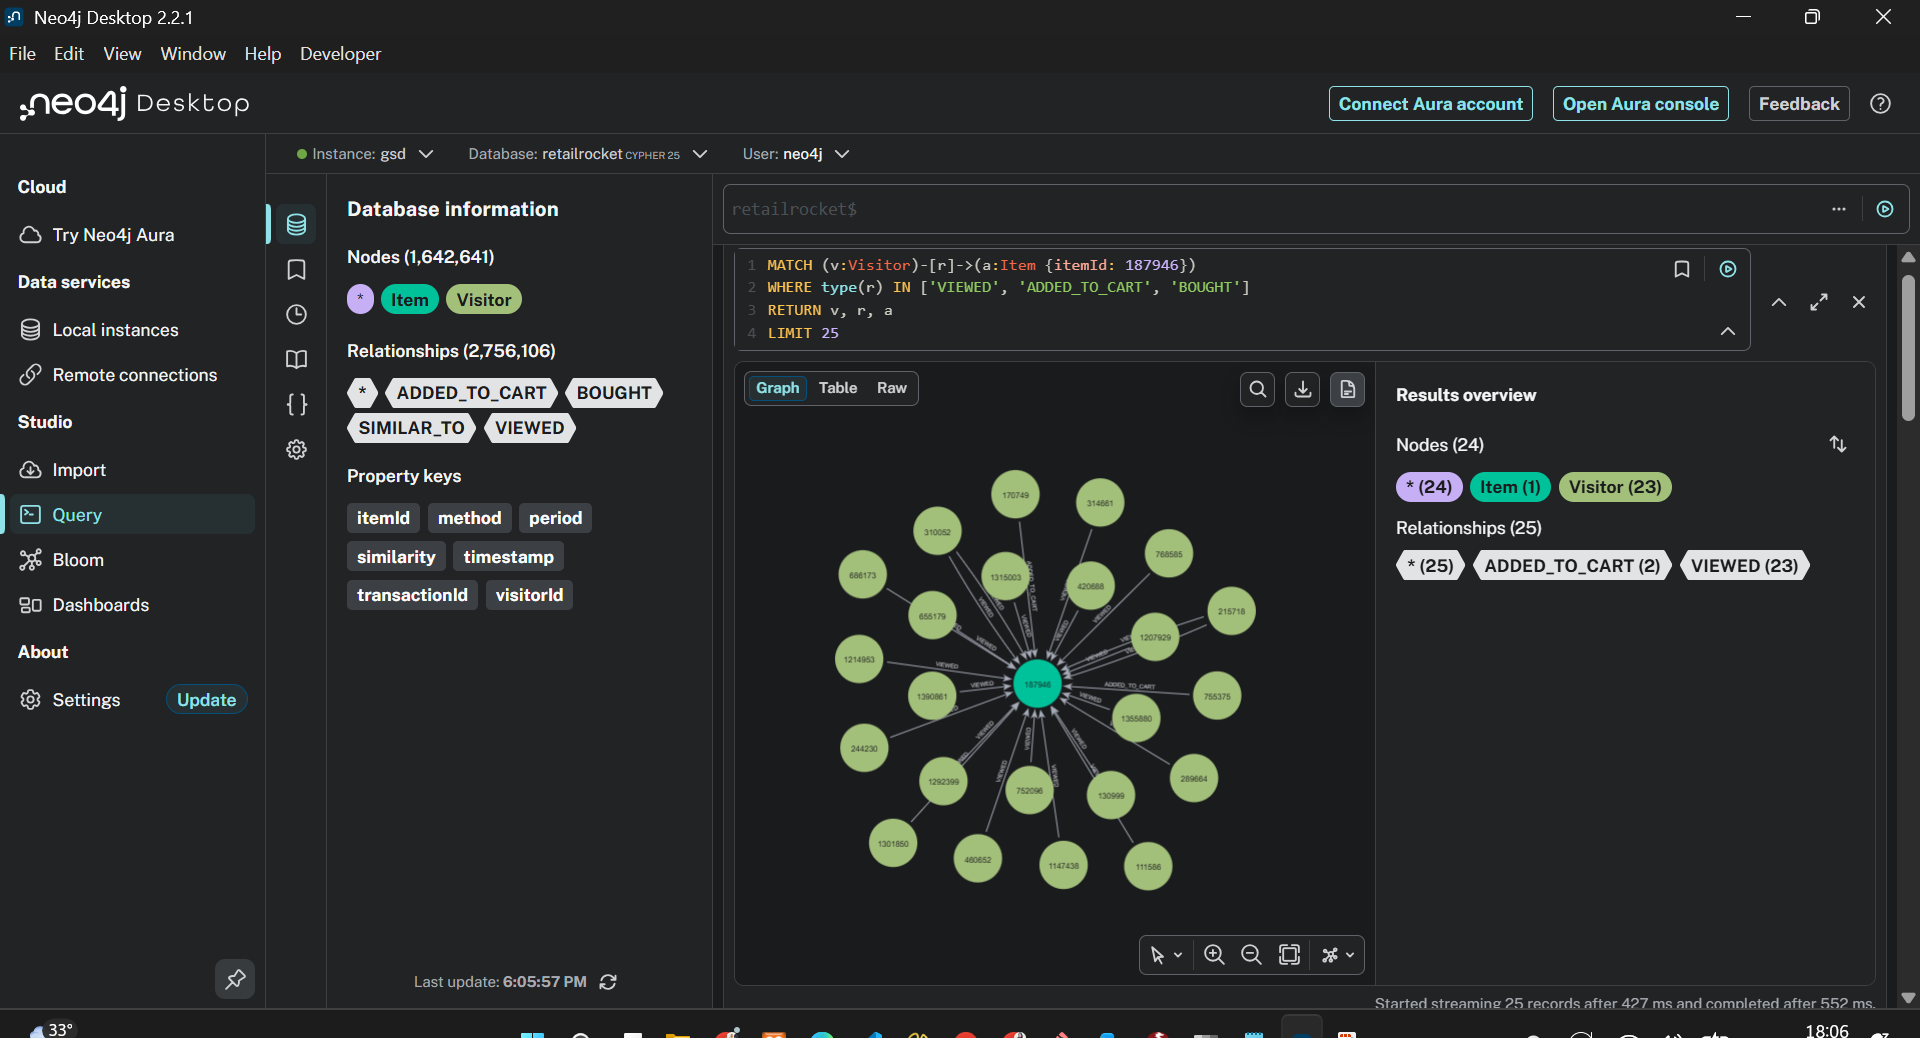

Pada kondisi awal, graf Neo4j merepresentasikan hubungan interaksi antara pengunjung (`Visitor`) dan produk (`Item`) berdasarkan aktivitas yang tercatat pada dataset RetailRocket. Relationship yang digunakan meliputi `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Pada tahap ini, visualisasi difokuskan pada hubungan interaksi asli yang melibatkan produk acuan dengan ID `187946`, sebelum relationship `SIMILAR_TO` ditambahkan sebagai hasil perhitungan similarity.

Untuk menampilkan kondisi tersebut, digunakan query Cypher berikut.

```cypher
MATCH (v:Visitor)-[r]->(a:Item {itemId: 187946})
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN v, r, a
LIMIT 25
```

Query tersebut mencari pengunjung yang memiliki hubungan interaksi dengan produk `187946`. Klausa `WHERE` membatasi hasil pada tiga jenis relationship interaksi asli, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Klausa `LIMIT 25` membatasi hasil menjadi maksimal 25 record agar struktur graf lebih mudah diamati.

**Hasil graf sebelum perhitungan similarity**

Berdasarkan hasil percobaan di Neo4j Desktop, query menghasilkan visualisasi yang terdiri atas simpul `Visitor` dan satu simpul `Item` dengan ID `187946`, yang dihubungkan oleh relationship interaksi. Hasil yang ditampilkan dibatasi maksimal 25 record dan memperlihatkan bagaimana pengunjung berinteraksi dengan produk acuan melalui aktivitas yang tercatat pada dataset.

Visualisasi ini menggambarkan hubungan interaksi antara pengunjung dan produk, bukan hubungan kemiripan antarproduk.

#### <span style="color:#ecf2fb;"><b> ▌ Kondisi Graf Sesudah Perhitungan Similarity </b></span>



![Gambar 2.8.2 — Graf Similarity Setelah Perhitungan.png](<attachment:Gambar 2.8.2 — Graf Similarity Setelah Perhitungan.png>)
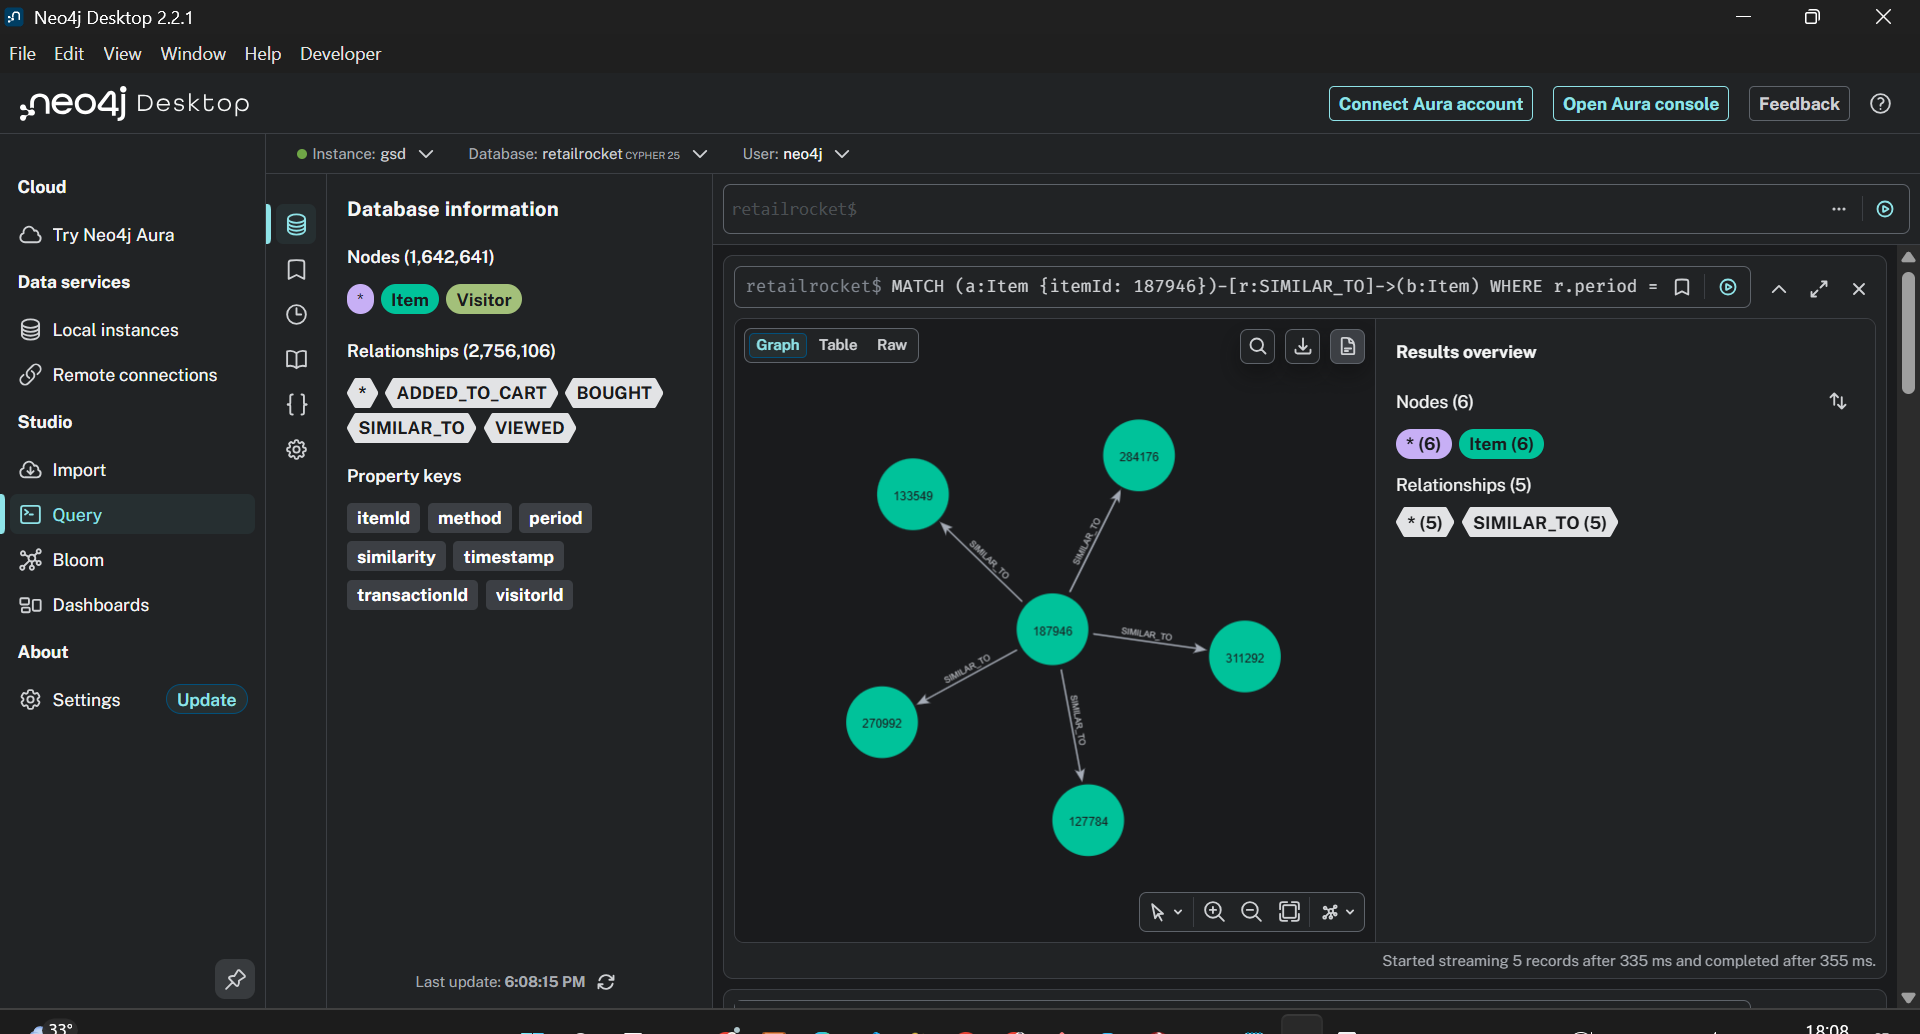

Setelah perhitungan *cosine similarity* dilakukan menggunakan Python pada matriks Item–User, lima produk dengan nilai similarity positif tertinggi dipilih berdasarkan pola interaksi pengguna. Produk acuan yang digunakan adalah produk `187946`, dengan jumlah 2.650 interaksi pada periode training P1.

Hasil perhitungan tersebut kemudian disimpan ke dalam graf Neo4j menggunakan relationship `SIMILAR_TO`. Setiap relationship menghubungkan produk acuan dengan produk kandidat dan memiliki properti `similarity`, `period`, serta `method`.

Untuk menampilkan kondisi graf setelah penambahan relationship similarity, digunakan query Cypher berikut.

```cypher
MATCH (a:Item {itemId: 187946})-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN a, r, b
ORDER BY r.similarity DESC
LIMIT 5
```

Query tersebut mencari produk acuan `187946` yang terhubung dengan produk lain melalui relationship `SIMILAR_TO`. Klausa `WHERE` membatasi hasil pada periode P1, sedangkan `ORDER BY` mengurutkan relationship berdasarkan nilai similarity tertinggi. Klausa `LIMIT 5` membatasi visualisasi menjadi lima hubungan similarity teratas.

**Hasil graf sesudah perhitungan similarity**

Berdasarkan hasil percobaan di Neo4j Desktop, graf menampilkan enam simpul `Item`, yang terdiri atas satu produk acuan dan lima produk dengan kemiripan tertinggi. Keenam simpul tersebut dihubungkan oleh lima relationship `SIMILAR_TO`.

Lima produk yang terhubung dengan produk acuan `187946` beserta nilai similarity-nya adalah sebagai berikut.

| Produk Acuan | Produk Mirip | Cosine Similarity |
|---:|---:|---:|
| 187946 | 127784 | 0,057290 |
| 187946 | 311292 | 0,052876 |
| 187946 | 284176 | 0,037244 |
| 187946 | 133549 | 0,033309 |
| 187946 | 270992 | 0,030528 |

Untuk memperlihatkan nilai similarity secara lebih terperinci, digunakan query berikut.

```cypher
MATCH (a:Item {itemId: 187946})-[r:SIMILAR_TO]->(b:Item)
WHERE r.period = 'P1'
RETURN
    a.itemId AS reference_item,
    b.itemId AS similar_item,
    r.similarity AS similarity
ORDER BY similarity DESC, similar_item ASC
LIMIT 5
```

Hasil query menampilkan lima pasangan produk beserta nilai similarity masing-masing. Produk `127784` memiliki nilai similarity tertinggi sebesar 0,057290, diikuti produk `311292` sebesar 0,052876, produk `284176` sebesar 0,037244, produk `133549` sebesar 0,033309, dan produk `270992` sebesar 0,030528.

Nilai tersebut sesuai dengan hasil perhitungan *cosine similarity* menggunakan Python pada soal nomor 7. Hal ini menunjukkan bahwa hasil perhitungan berhasil disimpan ke dalam graf Neo4j dan dapat dibaca kembali melalui query Cypher.

#### <span style="color:#ecf2fb;"><b> ▌ Perbandingan Kondisi Graf Sebelum dan Sesudah </b></span>

Perbedaan kondisi graf sebelum dan sesudah perhitungan similarity dapat dilihat berdasarkan jenis simpul dan relationship yang ditampilkan.

| Aspek | Sebelum Perhitungan Similarity | Sesudah Perhitungan Similarity |
|---|---|---|
| Simpul utama | `Visitor` dan `Item` | `Item` |
| Produk acuan | `187946` | `187946` |
| Jenis relationship yang ditampilkan | `VIEWED`, `ADDED_TO_CART`, `BOUGHT` | `SIMILAR_TO` |
| Makna hubungan | Interaksi pengunjung terhadap produk | Kemiripan pola interaksi antarproduk |
| Hasil visualisasi | Hubungan pengunjung dengan produk acuan | Produk acuan yang terhubung dengan lima produk mirip |

Pada kondisi sebelum perhitungan similarity, graf memperlihatkan aktivitas interaksi pengunjung terhadap produk acuan. Setelah perhitungan dilakukan, graf memiliki relationship tambahan berupa `SIMILAR_TO` yang menghubungkan produk acuan dengan lima produk yang memiliki pola interaksi serupa. Dengan demikian, graf tidak hanya merepresentasikan aktivitas pengguna, tetapi juga menyimpan hasil analisis kemiripan antarproduk.

![Gambar 2.8.3 — Verifikasi Nilai Similarity-2.png](<attachment:Gambar 2.8.3 — Verifikasi Nilai Similarity-2.png>)
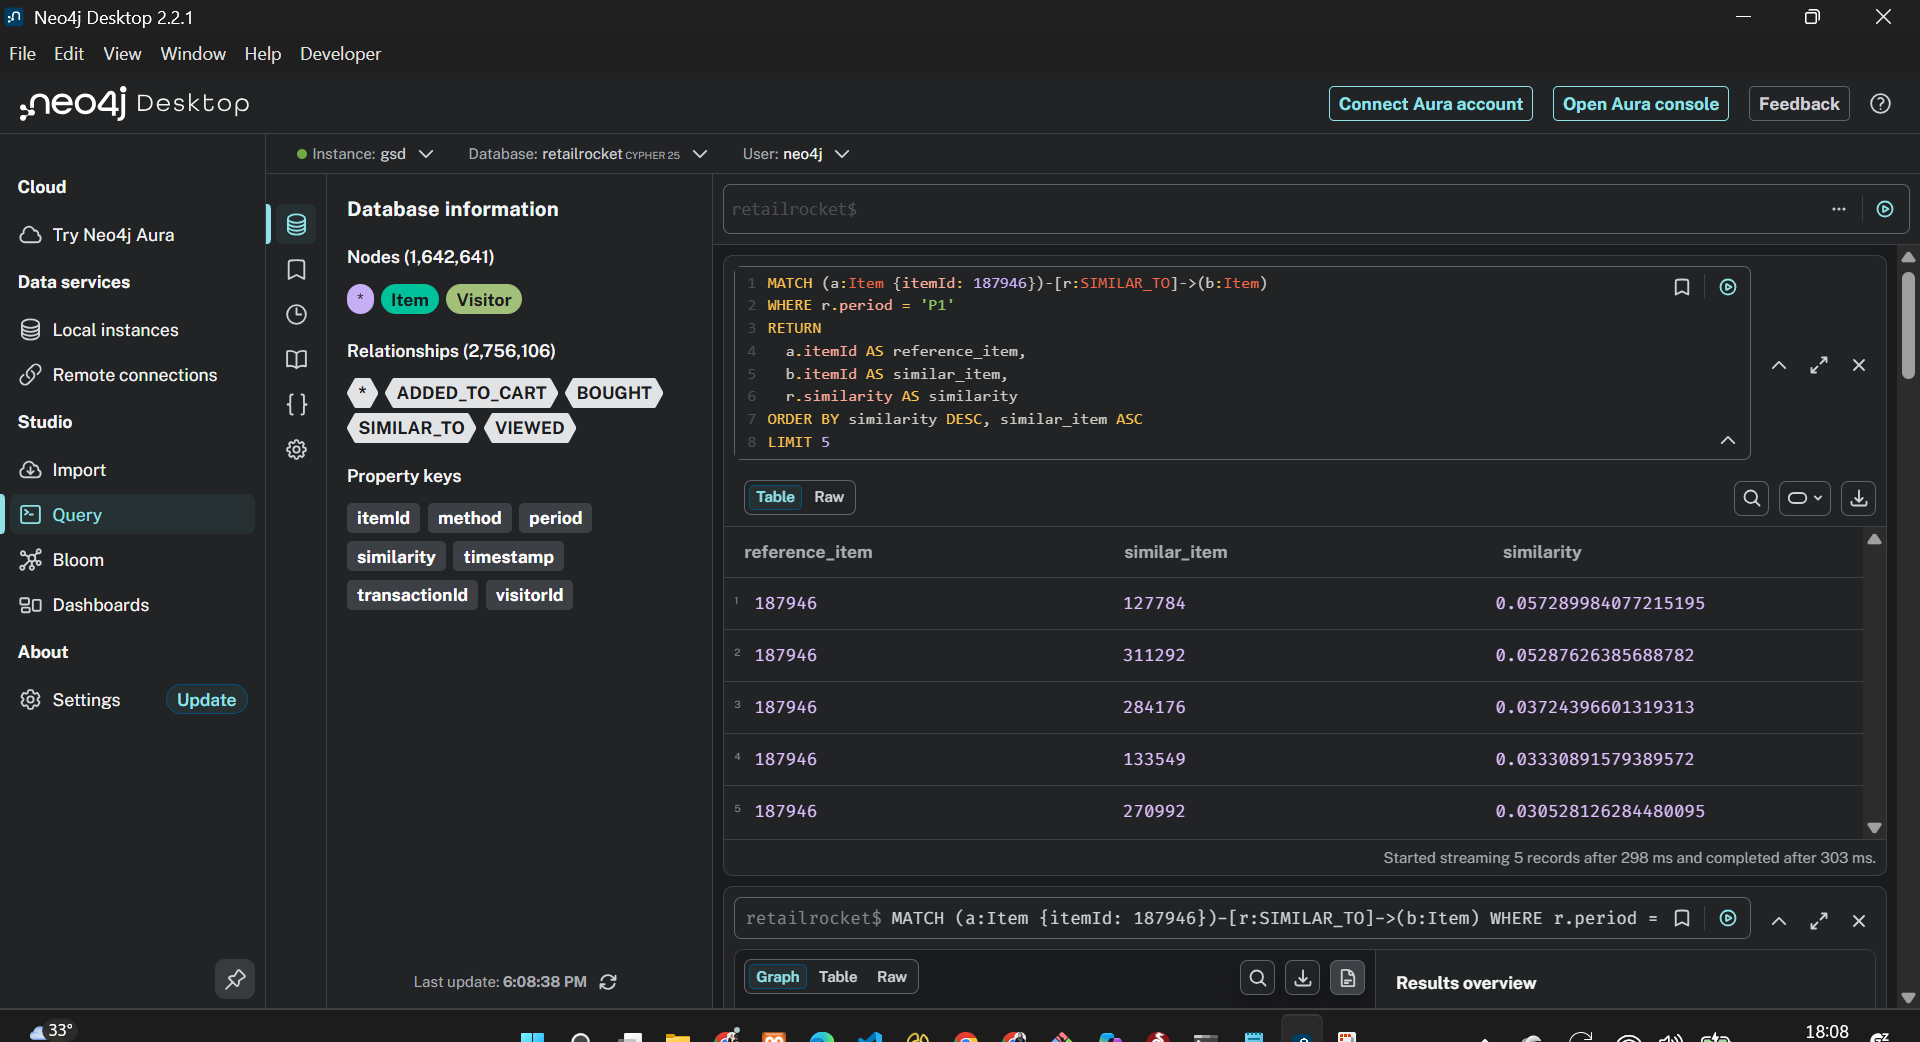

#### <span style="color:#ecf2fb;"><b> ▌ Kesimpulan </b></span>

Berdasarkan hasil visualisasi menggunakan Neo4j Desktop, kondisi graf sebelum perhitungan similarity memperlihatkan hubungan interaksi antara `Visitor` dan `Item` melalui relationship `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Setelah perhitungan *cosine similarity* menggunakan Python, hasil analisis disimpan ke dalam graf melalui relationship `SIMILAR_TO` yang menghubungkan produk acuan `187946` dengan lima produk yang memiliki nilai similarity tertinggi.

Hasil query Cypher menunjukkan bahwa kelima relationship tersebut memiliki nilai similarity yang sesuai dengan hasil perhitungan Python. Perbandingan ini memperlihatkan bahwa graf Neo4j dapat digunakan untuk menyimpan dan memvisualisasikan hubungan interaksi sekaligus hasil analisis kemiripan antarproduk sebagai dasar pengembangan sistem rekomendasi.

---
### **2.2 Analytics**
---

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 01
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Rekomendasi Item Menggunakan K-Nearest Neighbors (KNN)
  </h2>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

#### <span style="color:#ecf2fb;"><b> ▌ a) Pemilihan User secara Acak dan Implementasi KNN </b></span>

In [46]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

# memilih user secara acak dengan seed tetap
random_state = 42
rng = np.random.default_rng(random_state)

# memilih user yang memiliki interaksi pada P1 dan P2
train_users = set(p1["visitorid"].unique())
test_users = set(p2["visitorid"].unique())

eligible_users = np.array(
    sorted(train_users.intersection(test_users))
)

if len(eligible_users) == 0:
    raise ValueError(
        "Tidak ada user yang memiliki interaksi pada P1 dan P2."
    )

target_user = int(rng.choice(eligible_users))
target_idx = user_to_idx[target_user]

print("Random state:", random_state)
print("Jumlah user kandidat:", len(eligible_users))
print("User terpilih:", target_user)

# menghitung cosine similarity user target terhadap seluruh user
user_similarity = cosine_similarity(
    X_user_item[target_idx],
    X_user_item
).ravel()

# mengurutkan user berdasarkan similarity tertinggi
neighbor_order = np.argsort(-user_similarity)

# memilih lima tetangga terdekat tanpa user target
neighbors = [
    idx for idx in neighbor_order
    if idx != target_idx and user_similarity[idx] > 0
][:5]

if len(neighbors) < 5:
    raise ValueError(
        "Kurang dari lima tetangga dengan similarity positif."
    )

# menyimpan ID dan nilai similarity tetangga
neighbor_ids = users[neighbors]
neighbor_scores = user_similarity[neighbors]

neighbors_df = pd.DataFrame({
    "visitorid": neighbor_ids,
    "similarity": neighbor_scores
})

print("\n=== LIMA NEAREST NEIGHBORS ===")
display(neighbors_df)

Random state: 42
Jumlah user kandidat: 8699
User terpilih: 129611

=== LIMA NEAREST NEIGHBORS ===


,visitorid,similarity
0,73624,0.478091
1,368591,0.428571
2,990451,0.400892
3,484795,0.377964
4,571440,0.377964


**Penjelasan hasil**

Berdasarkan hasil implementasi algoritma K-Nearest Neighbors (KNN), terdapat 8.699 user yang memiliki interaksi pada periode training (P1) dan testing (P2). Pemilihan user dilakukan secara acak menggunakan nilai *random state* sebesar 42 agar proses pemilihan dapat direproduksi. Hasilnya, user dengan ID **129611** terpilih sebagai user target.

Selanjutnya, kemiripan antara user target dan user lainnya dihitung menggunakan *cosine similarity* berdasarkan matriks User–Item yang dibentuk dari data training. Lima user dengan nilai kemiripan tertinggi dipilih sebagai tetangga terdekat (*nearest neighbors*), yaitu user 73624 dengan nilai similarity 0,478091, user 368591 sebesar 0,428571, user 990451 sebesar 0,400892, serta user 484795 dan 571440 yang masing-masing memiliki nilai similarity 0,377964.

Nilai *cosine similarity* yang positif menunjukkan adanya kemiripan pola interaksi antara user target dan kelima tetangganya. User 73624 memiliki nilai kemiripan tertinggi di antara kelima tetangga tersebut, sedangkan user 484795 dan 571440 memiliki nilai kemiripan terendah dengan nilai yang sama. Kelima tetangga ini selanjutnya digunakan untuk menghitung skor rekomendasi berdasarkan interaksi mereka terhadap berbagai item pada periode training.

#### <span style="color:#ecf2fb;"><b> ▌ b) Hasil Rekomendasi Tiga Item untuk k = 5 </b></span>

In [47]:
# memberikan bobot pada interaksi berdasarkan similarity tetangga
weighted_interactions = X_user_item[neighbors].multiply(
    neighbor_scores.reshape(-1, 1)
)

# menjumlahkan skor interaksi berbobot untuk setiap item
item_scores = np.asarray(
    weighted_interactions.sum(axis=0)
).ravel()

# mengambil item yang sudah pernah berinteraksi dengan user target pada P1
seen_items = set(
    p1.loc[
        p1["visitorid"] == target_user,
        "itemid"
    ].unique()
)

# menyusun kandidat rekomendasi
recommendation_df = pd.DataFrame({
    "itemid": items,
    "recommendation_score": item_scores
})

# menghapus item yang sudah pernah dilihat atau berinteraksi dengan user
recommendation_df = recommendation_df[
    (recommendation_df["recommendation_score"] > 0)
    & (~recommendation_df["itemid"].isin(seen_items))
].copy()

# mengurutkan dan mengambil lima rekomendasi teratas
recommendation_df = (
    recommendation_df
    .sort_values(
        ["recommendation_score", "itemid"],
        ascending=[False, True]
    )
    .head(5)
    .reset_index(drop=True)
)

recommendation_df.insert(
    0,
    "rank",
    np.arange(1, len(recommendation_df) + 1)
)

if len(recommendation_df) < 5:
    raise ValueError(
        "Kurang dari lima kandidat rekomendasi tersedia."
    )

# menampilkan tiga item rekomendasi teratas
top3_recommendations = recommendation_df.head(3)

print("User target:", target_user)
print("\n=== TIGA ITEM REKOMENDASI ===")
display(top3_recommendations)

User target: 129611

=== TIGA ITEM REKOMENDASI ===


,rank,itemid,recommendation_score
0,1,326551,0.956183
1,2,308283,0.478091
2,3,408189,0.478091


**Penjelasan hasil**

Berdasarkan penerapan KNN dengan lima tetangga terdekat (\(k = 5\)), sistem menghasilkan tiga rekomendasi item teratas untuk user target dengan ID 129611. Skor rekomendasi dihitung dengan menjumlahkan frekuensi interaksi setiap item dari kelima tetangga setelah diberi bobot berdasarkan nilai *cosine similarity* masing-masing tetangga terhadap user target.

Hasil perhitungan menunjukkan bahwa item dengan ID **326551** menempati peringkat pertama dengan skor rekomendasi sebesar **0,956183**. Selanjutnya, item 308283 dan item 408189 masing-masing menempati peringkat kedua dan ketiga dengan skor sebesar 0,478091.

Skor rekomendasi item 326551 yang lebih tinggi menunjukkan bahwa item tersebut memperoleh dukungan interaksi berbobot yang lebih besar dari kelima tetangga dibandingkan dua item lainnya. Sementara itu, item 308283 dan 408189 memiliki skor yang sama sehingga keduanya memperoleh peringkat yang berurutan berdasarkan aturan pengurutan ID item secara menaik.

Dalam proses rekomendasi, item yang telah memiliki riwayat interaksi dengan user target pada periode training dikeluarkan dari kandidat. Dengan demikian, sistem menghasilkan tiga kandidat item yang belum pernah berinteraksi dengan user target pada P1 dan memiliki skor rekomendasi tertinggi berdasarkan pola interaksi tetangga terdekat.

<div style="background:#172554; padding:20px 24px; border-radius:10px; margin-bottom:20px;">
  <div style="color:#93c5fd; font-size:11px; letter-spacing:2px; font-weight:600;">
    SOAL · 02
  </div>
  <h2 style="color:#ffffff; margin:8px 0; border:none;">
    Analytics
  </h2>
  <div style="background:#60a5fa; height:3px; width:54px; margin-top:12px; border-radius:10px;"></div>
</div>

#### <span style="color:#ecf2fb;"><b> ▌ a) Perhitungan Hit@5 </b></span>

Evaluasi dilakukan berdasarkan hasil rekomendasi yang diperoleh dari model K-Nearest Neighbors (KNN) dengan \(k=5\). Lima item rekomendasi teratas dibandingkan dengan item yang berinteraksi dengan pengguna target pada periode pengujian (P2). Evaluasi dilakukan menggunakan dua metrik, yaitu Hit@5 untuk mengukur keberadaan item relevan dalam lima rekomendasi teratas dan NDCG@5 untuk mengukur relevansi serta posisi item dalam daftar rekomendasi.

In [48]:
# mengambil lima rekomendasi teratas
top5_recommendations = recommendation_df.head(5).copy()

# mengambil item yang berinteraksi dengan user pada periode testing (P2)
relevant_items = set(
    p2.loc[
        p2["visitorid"] == target_user,
        "itemid"
    ].unique()
)

# memeriksa apakah setiap rekomendasi relevan
top5_recommendations["relevant"] = (
    top5_recommendations["itemid"]
    .isin(relevant_items)
    .astype(int)
)

# menghitung Hit@5
hit_at_5 = int(
    top5_recommendations["relevant"].sum() > 0
)

print("User target:", target_user)
print("Jumlah item relevan pada P2:", len(relevant_items))

print("\n=== EVALUASI LIMA REKOMENDASI ===")
display(top5_recommendations)

print("Hit@5:", hit_at_5)

User target: 129611
Jumlah item relevan pada P2: 4

=== EVALUASI LIMA REKOMENDASI ===


,rank,itemid,recommendation_score,relevant
0,1,326551,0.956183,0
1,2,308283,0.478091,0
2,3,408189,0.478091,0
3,4,76644,0.428571,0
4,5,248032,0.428571,0


Hit@5: 0


**Penjelasan hasil**

Evaluasi rekomendasi dilakukan dengan membandingkan lima item rekomendasi teratas terhadap item yang berinteraksi dengan pengguna target pada periode pengujian (P2). Pengguna yang dievaluasi adalah pengguna dengan ID 129611, yang memiliki empat item relevan pada P2.

Berdasarkan hasil evaluasi, kelima item rekomendasi, yaitu 326551, 308283, 408189, 76644, dan 248032, tidak ditemukan dalam daftar item relevan pengguna pada periode P2. Oleh karena itu, tidak terdapat item relevan pada lima rekomendasi teratas.

Nilai Hit@5 yang diperoleh adalah 0. Hasil ini menunjukkan bahwa sistem rekomendasi K-Nearest Neighbors (KNN) belum berhasil memberikan setidaknya satu rekomendasi yang sesuai dengan interaksi pengguna target selama periode pengujian.

#### <span style="color:#ecf2fb;"><b> ▌ b) Perhitungan NDCG@5 </b></span>

In [49]:
# mengambil nilai relevansi dari lima rekomendasi
relevance = top5_recommendations["relevant"].to_numpy()

# menghitung DCG@5
positions = np.arange(1, len(relevance) + 1)

dcg_at_5 = np.sum(
    relevance / np.log2(positions + 1)
)

# menghitung IDCG@5 berdasarkan jumlah item relevan pada P2
ideal_length = min(5, len(relevant_items))

if ideal_length > 0:
    ideal_relevance = np.ones(ideal_length)

    ideal_positions = np.arange(1, ideal_length + 1)

    idcg_at_5 = np.sum(
        ideal_relevance / np.log2(ideal_positions + 1)
    )
else:
    idcg_at_5 = 0.0

# menghitung NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("Relevance:", relevance.tolist())
print("DCG@5:", round(dcg_at_5, 6))
print("IDCG@5:", round(idcg_at_5, 6))
print("NDCG@5:", round(ndcg_at_5, 6))

Relevance: [0, 0, 0, 0, 0]
DCG@5: 0.0
IDCG@5: 2.561606
NDCG@5: 0.0


**Penjelasan hasil**

Evaluasi juga dilakukan menggunakan Normalized Discounted Cumulative Gain pada lima rekomendasi teratas (NDCG@5). Metrik ini mempertimbangkan relevansi item sekaligus posisi item dalam daftar rekomendasi, dengan memberikan bobot lebih besar pada item relevan yang berada di peringkat lebih tinggi.

Hasil perhitungan menunjukkan bahwa vektor relevansi lima rekomendasi adalah [0, 0, 0, 0, 0]. Dengan demikian, nilai DCG@5 adalah 0, sedangkan IDCG@5 sebesar 2,561606. Nilai NDCG@5 yang diperoleh adalah 0,0. Hasil ini menunjukkan bahwa tidak ada item relevan yang berhasil ditempatkan dalam lima rekomendasi teratas. Temuan tersebut konsisten dengan nilai Hit@5 sebesar 0.

#### <span style="color:#ecf2fb;"><b> ▌ Kesimpulan </b></span>

Berdasarkan evaluasi terhadap pengguna target dengan ID 129611, model K-Nearest Neighbors (KNN) menghasilkan nilai Hit@5 sebesar 0 dan NDCG@5 sebesar 0,0. Hasil ini menunjukkan bahwa tidak ada item relevan yang berhasil ditempatkan dalam lima rekomendasi teratas untuk pengguna tersebut pada periode pengujian (P2). Meskipun demikian, hasil evaluasi ini hanya menggambarkan performa model pada satu pengguna yang dipilih secara acak dengan seed tetap, sehingga belum dapat digunakan untuk menyimpulkan performa model terhadap seluruh pengguna.

<div style="background:#60a5fa; width:100%; height:0.3px; border-radius:2px;"></div>

#
---

<div style="padding:16px 22px; border-radius:10px; margin:12px 0;">
  <div style="color:#93c5fd; font-size:12px; font-weight:600; letter-spacing:2px;">
    BAGIAN 03
  </div>
  <h2 style="color:white; margin:6px 0 10px 0; border:none;">
    Dokumentasi Upload Repository Github
  </h2>
  <div style="background:#60a5fa; width:55px; height:4px; border-radius:5px;"></div>
</div>

---

![Dokumentasi Proses Push github - 1.png](<attachment:Dokumentasi Proses Push github - 1.png>)
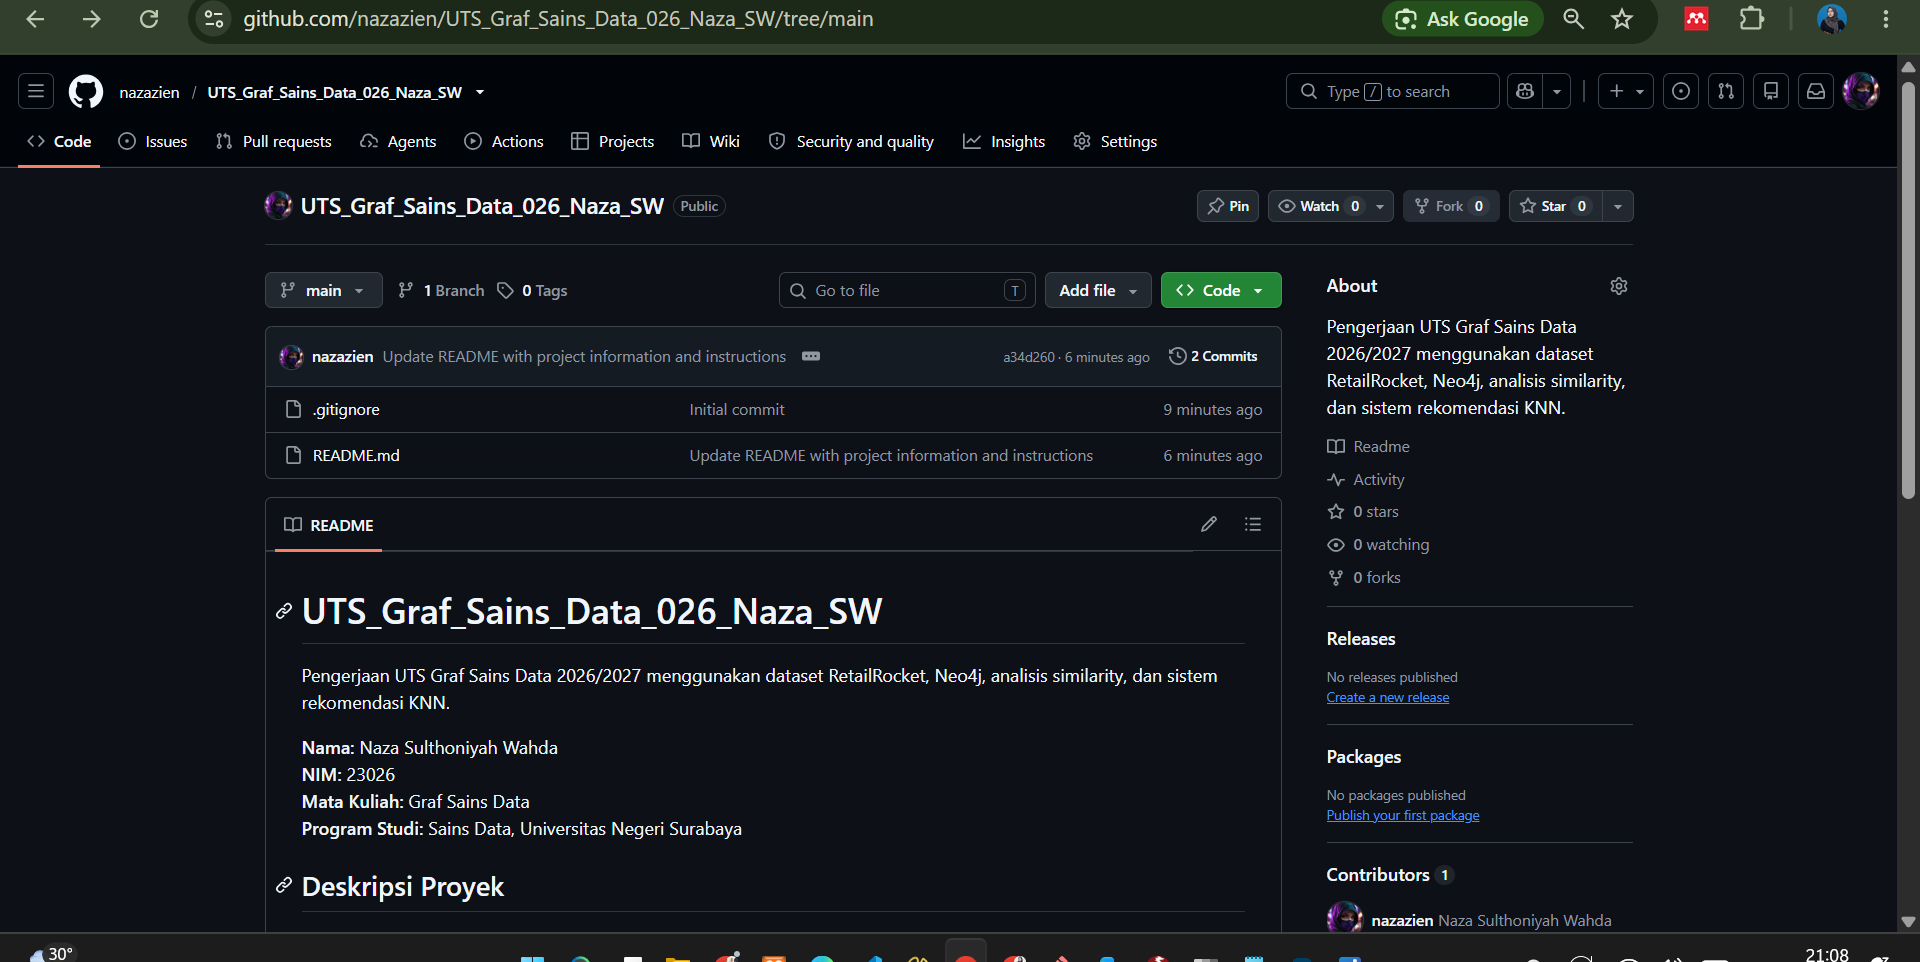
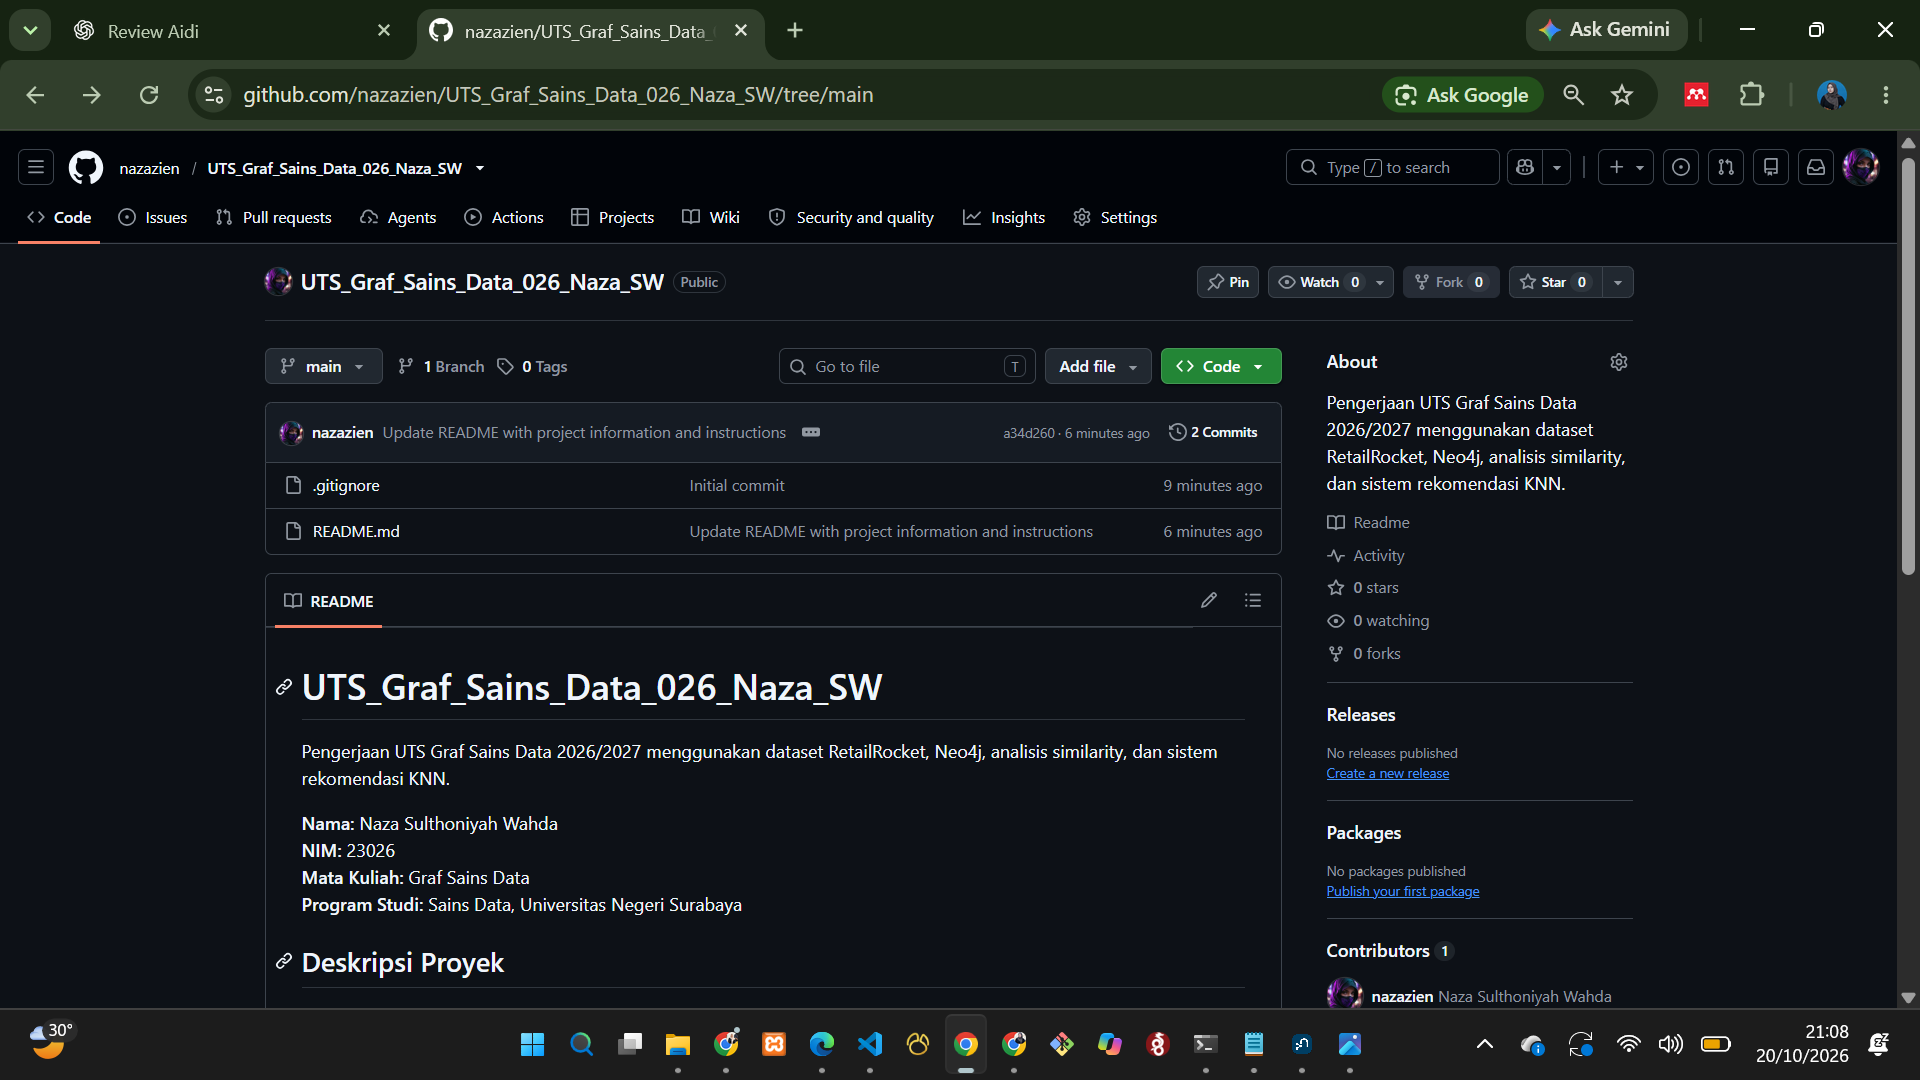

![Langkah 1.png](<attachment:Langkah 1.png>)
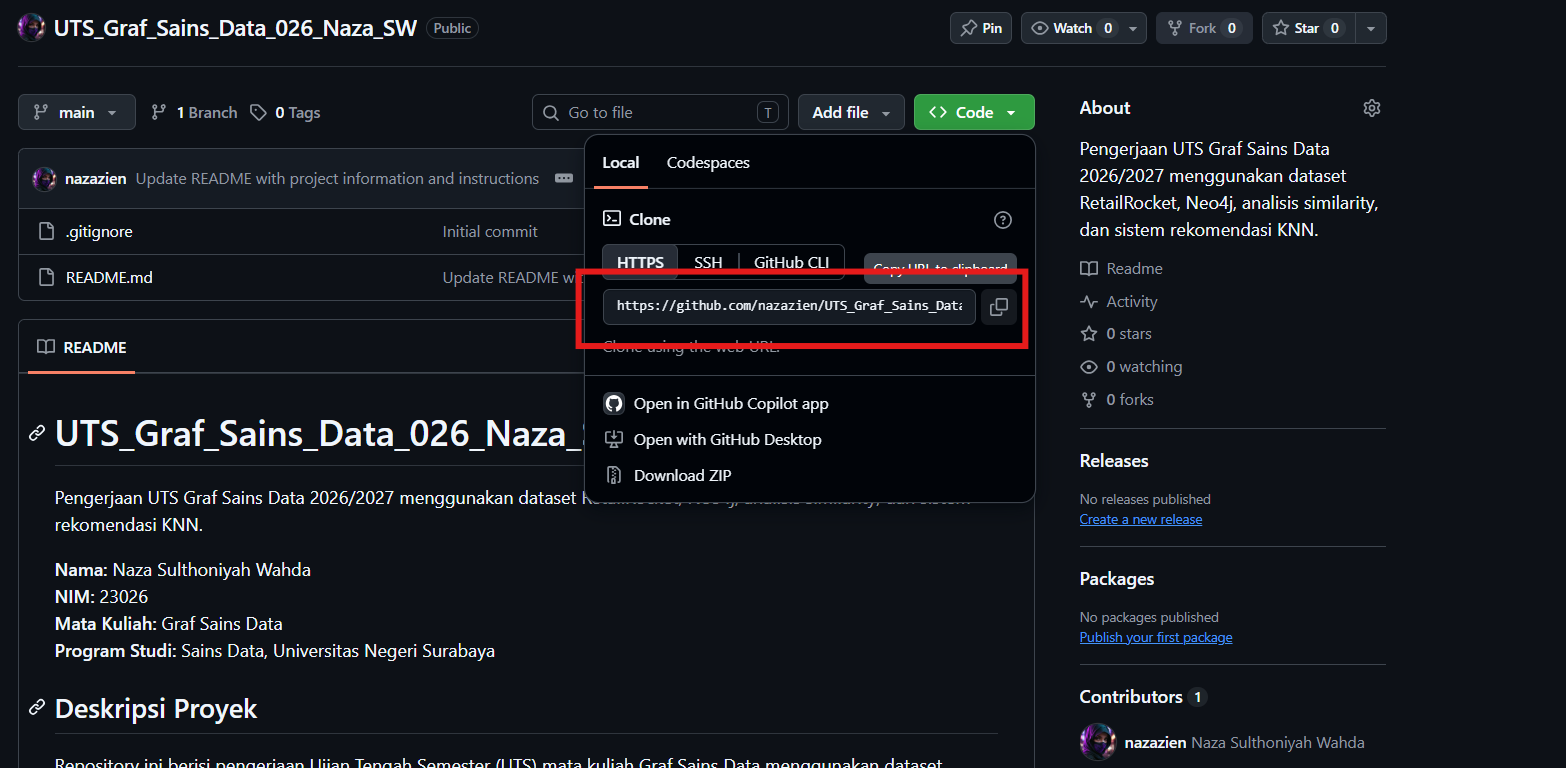

![Langkah 2.png](<attachment:Langkah 2.png>)
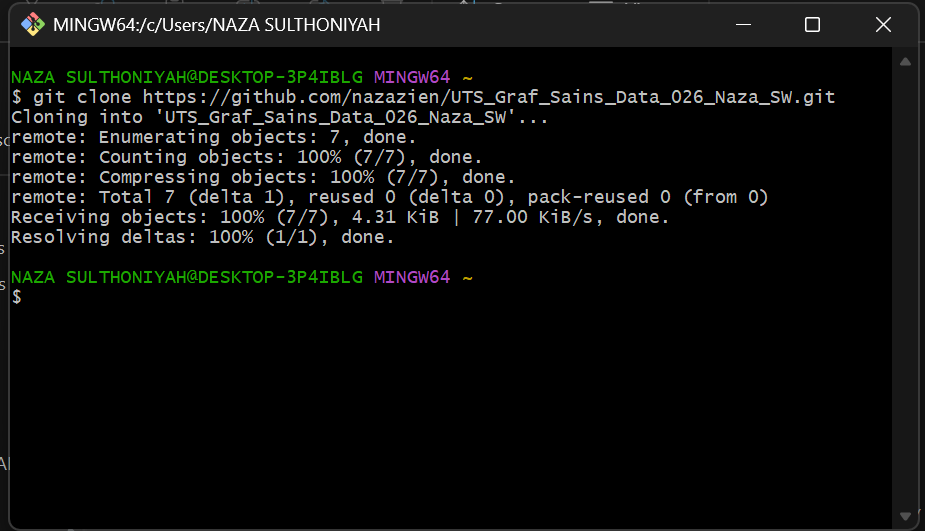

![Langkah 3.png](<attachment:Langkah 3.png>)
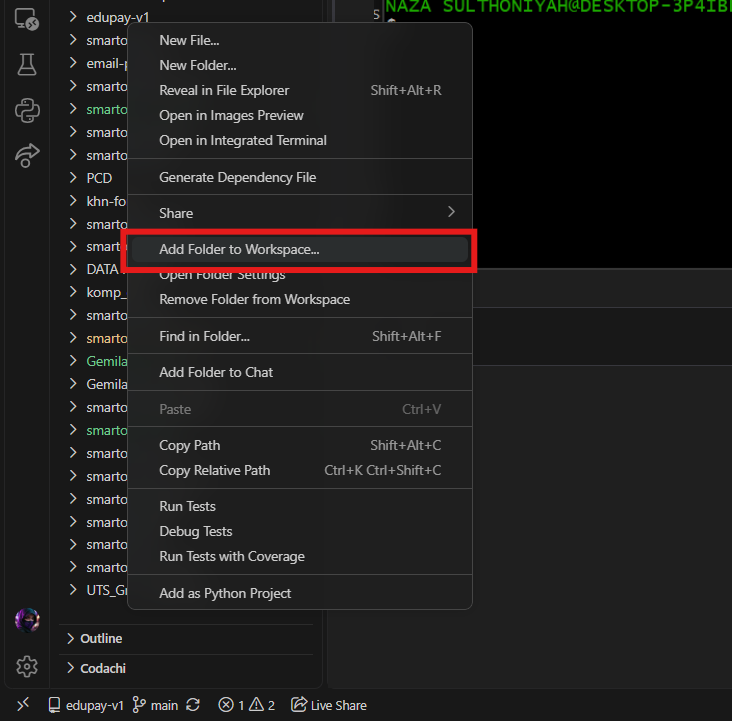

![Langkah 4.png](<attachment:Langkah 4.png>)
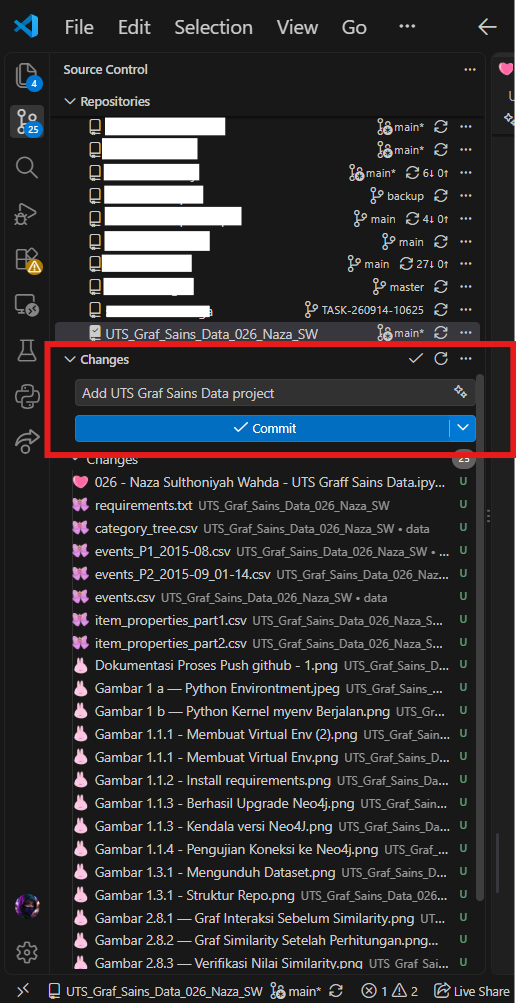

![langkah 5.png](<attachment:langkah 5.png>)
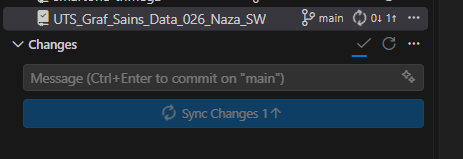

![Langkah 6.png](<attachment:Langkah 6.png>)
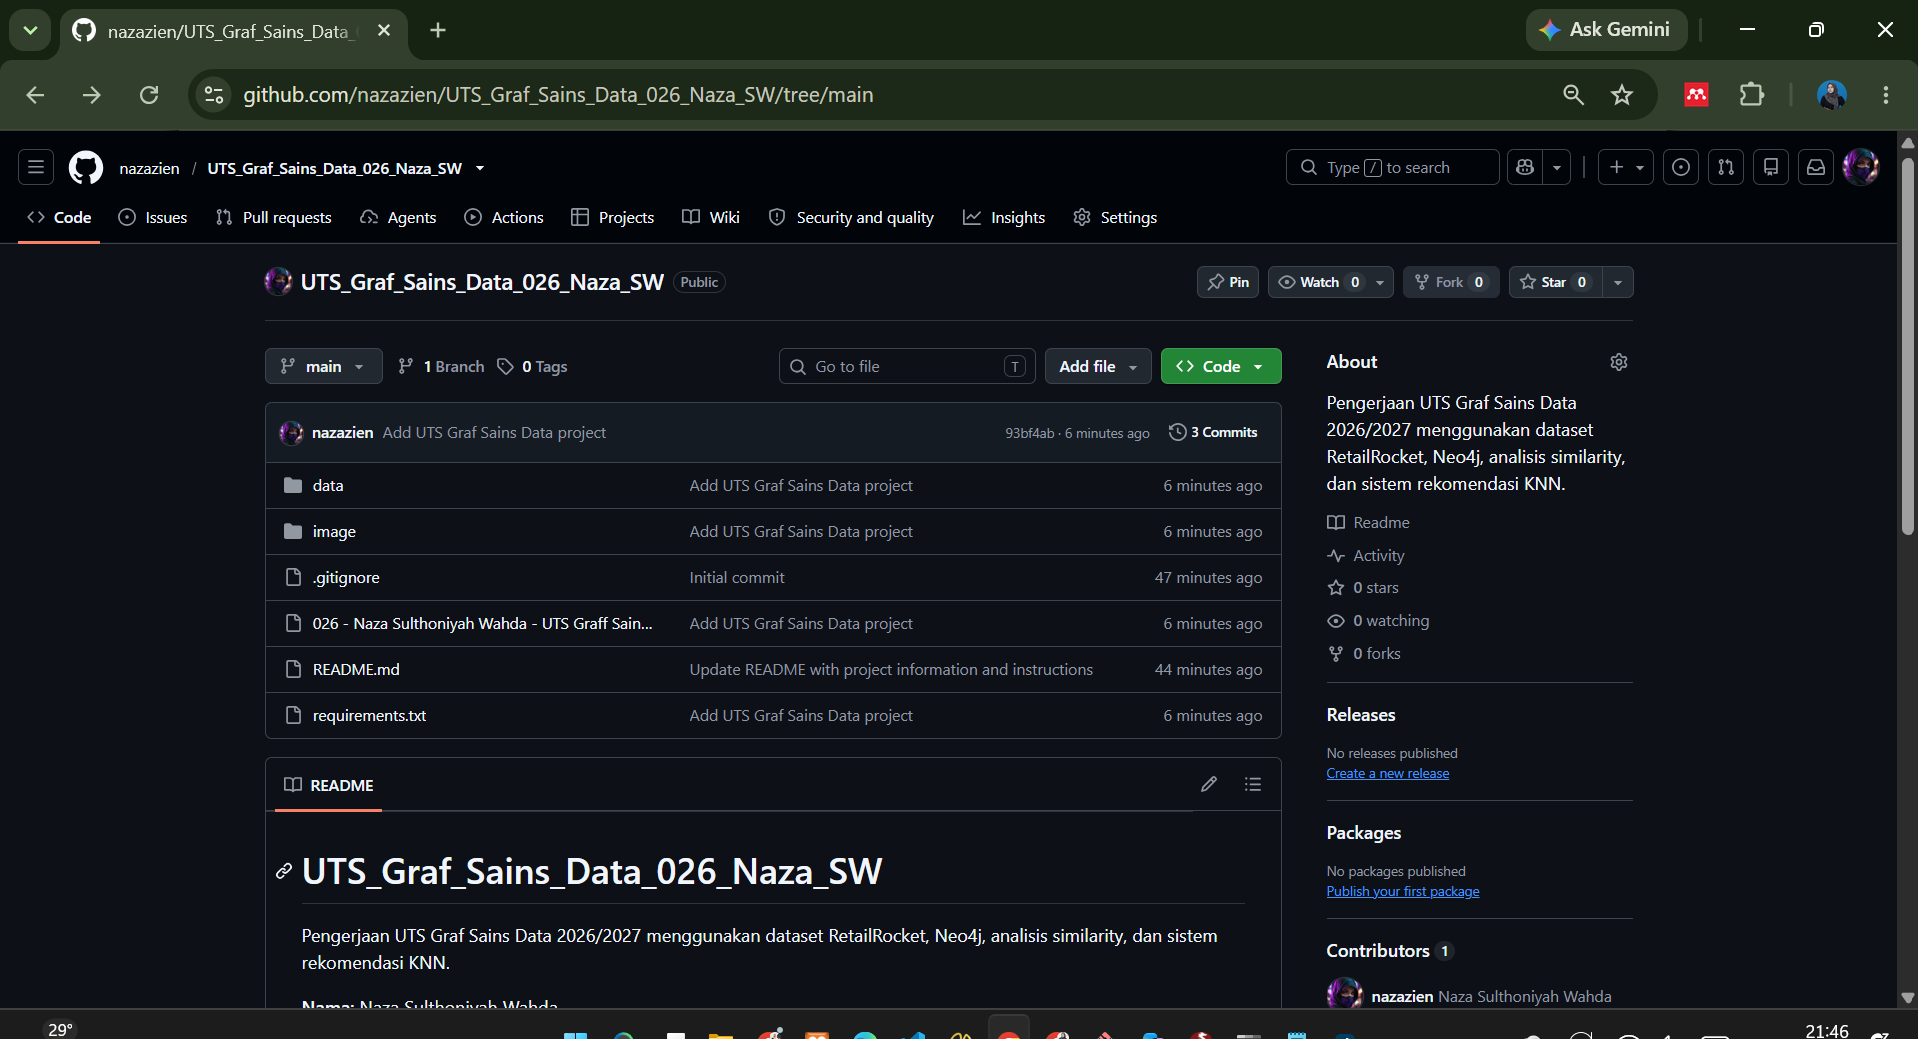

LINK Repository:

https://github.com/nazazien/UTS_Graf_Sains_Data_026_Naza_SW 

Terima kasih atas waktu dan perhatiannya Bapak/Ibu